# EDA of licit and illicit addresses

## 1. Configuration

### 1.1. CONSTANTS and Environment setup

In [1]:
import os
import pandas as pd
import numpy as np
from pathlib import Path
from varname import nameof
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
import psutil
warnings.filterwarnings("ignore")

In [2]:
# Resolve the project root even if Jupyter is launched from another directory.
CWD = Path().cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
while (not (PROJECT_ROOT / "pyproject.toml").exists()) and (PROJECT_ROOT != PROJECT_ROOT.parent):
    PROJECT_ROOT = PROJECT_ROOT.parent

ROOT = PROJECT_ROOT / "src"
SRC = PROJECT_ROOT / "datasets"
OUTPUT = PROJECT_ROOT / "outputs"
OUTPUT_VARIANTS = {
                    "EDA": OUTPUT / "EDA",
                    "data_cleaning": OUTPUT / "data_cleaning",
                    "data_visualization": OUTPUT / "data_visualization",
                    "hypothesis_testing": OUTPUT / "hypothesis_testing",
                    "threshold_finetuning": OUTPUT / "threshold_finetuning",
                    "ETL": OUTPUT / "ETL",
                  }
print(f"project root: {PROJECT_ROOT}")
print(f"src directory: {ROOT}")
print(f"dataset directory: {SRC}")
print(f"output directory: {OUTPUT}")


project root: /home/annoy/projects/team/capstone-1/dev/data_analysis
src directory: /home/annoy/projects/team/capstone-1/dev/data_analysis/src
dataset directory: /home/annoy/projects/team/capstone-1/dev/data_analysis/datasets
output directory: /home/annoy/projects/team/capstone-1/dev/data_analysis/outputs


In [3]:
OUTPUT.mkdir(parents = True, exist_ok=True)
print(f"{OUTPUT} is created.") if (OUTPUT.exists() and OUTPUT.is_dir()) else print(f"{OUTPUT} is not created")
for directory in OUTPUT_VARIANTS.values():
    (directory).mkdir(parents=True, exist_ok= True)
    if (directory).exists() and (directory).is_dir():
        print(f"{directory} is created.")

/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/EDA is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/data_cleaning is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/data_visualization is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/hypothesis_testing is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/threshold_finetuning is created.
/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/ETL is created.


### 1.2. Plotting configuration

In [4]:
sns.color_palette("deep")
# Value available: pastel, husl, Set2, Spectral, flare, deep

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

In [5]:
    # 1. Matplotlib Global Configuration (rcParams)
plt.rcParams.update({
    # Figure dimensions and resolution
    "figure.figsize": (8, 5),          # Standard aspect ratio for reports and notebooks
    "figure.dpi": 100,                 # Display resolution
    "savefig.dpi": 300,                # High-resolution export for publication
    "savefig.bbox": "tight",           # Prevent clipping of axis labels and titles

    # Typography
    "font.family": "sans-serif",       # Clean, readable default font family
    "font.sans-serif": ["DejaVu Sans", "Helvetica", "Arial"],
    "font.size": 11,                   # Base font size for readability
    "axes.titlesize": 13,              # Subplot title font size
    "axes.labelsize": 11,              # X and Y axis label font size
    "xtick.labelsize": 10,             # Tick label size
    "ytick.labelsize": 10,

    # Axes and Grid Styling
    "axes.grid": True,                 # Enable background grid for precise data tracking
    "grid.alpha": 0.3,                 # Subtle grid transparency to avoid overpowering data
    "grid.linestyle": "--",            # Dashed grid lines
    "axes.linewidth": 0.8,             # Spine line width
    "axes.edgecolor": "#333333",       # Dark gray spines instead of harsh pure black

    # Lines and Markers
    "lines.linewidth": 1.5,            # Default line thickness for plots
    "patch.linewidth": 0.5,            # Border width for histograms, bars, and KDE fills

    # Layout Management
    "figure.autolayout": True          # Automatic tight layout padding adjustment
})
print(f"Loaded Mathplotlib Configuration")

sns.set_theme(style="whitegrid", palette="deep", font="sans-serif")
print(f"Loaded Seaborn Configuration")


Loaded Mathplotlib Configuration
Loaded Seaborn Configuration


### 1.3. Functions

In [6]:
from src.scripts.ETL import load_analysis_tables, print_ingestion_status

try:
    mirror_status = print_ingestion_status()
    if not mirror_status.empty and (mirror_status["status"] != "completed").any():
        print("WARNING: ETL is still running; the tables below are partial.")

    # Initialize process handle for system-level resource inspection
    process = psutil.Process(os.getpid())
    
    # Capture baseline CPU core time ticks and Resident Set Size (RSS) memory
    cpu_times_before = process.cpu_times()
    mem_before = process.memory_info().rss / (1024 * 1024)  # Converted to MB

    start_load_file_duration = time.time()

    # Execute data loading unconditionally to prevent NameError downstream
    (
        suspicious_account_data,
        suspicious_transactions_data,
        suspicious_blacklisted_data,
        suspicious_wallet_hops_data,
    ) = load_analysis_tables()

    load_duration = time.time() - start_load_file_duration

    # Capture post-execution resource metrics
    mem_after = process.memory_info().rss / (1024 * 1024)  # Converted to MB
    cpu_times_after = process.cpu_times()

    # Compute exact CPU time consumed (user + system space) during data loading
    cpu_time_consumed = (cpu_times_after.user - cpu_times_before.user) + (
        cpu_times_after.system - cpu_times_before.system
    )
    # Approximate effective core saturation percentage over the duration window
    effective_core_pct = (cpu_time_consumed / load_duration) * 100 if load_duration > 0 else 0.0

    print(f"Duration: {load_duration:.4f} seconds")
    print(f"Memory Delta: {mem_after - mem_before:.2f} MB (Total RSS: {mem_after:.2f} MB)")
    print(f"CPU Time Consumed: {cpu_time_consumed:.2f}s (~{effective_core_pct:.1f}% single-core equivalent load)")

except Exception as error:
    raise RuntimeError(
        "Could not read the local mirror. Run "
        "`python3 src/scripts/ETL.py --workers 5` first, then rerun this cell."
    ) from error

# Keep this order aligned with load_analysis_tables().
all_dfs = [
    suspicious_account_data,
    suspicious_transactions_data,
    suspicious_blacklisted_data,
    suspicious_wallet_hops_data,
]
all_dfs_name = [
    "suspicious_account_data",
    "suspicious_transactions_data",
    "suspicious_blacklisted_data",
    "suspicious_wallet_hops_data",
]

print("Loaded analysis tables from the local mirror.")

         table_name  source_rows  ingested_rows  progress_percent    status
blacklisted_wallets      11418.0        11418.0             100.0 completed
Duration: 739.4399 seconds
Memory Delta: 3322.64 MB (Total RSS: 3548.19 MB)
CPU Time Consumed: 340.43s (~46.0% single-core equivalent load)
Loaded analysis tables from the local mirror.


### 1.3.1 ETL boundary

`src/scripts/ETL.py` owns every database write. The notebook only calls
`load_analysis_tables()`, which reads the local PostgreSQL mirror.

```bash
# terminal 1 - batch ingestion, up to 5 worker processes
python3 src/scripts/ETL.py --workers 5 --batch-size 50000

# terminal 2 - inspect progress while ingestion is still running
python3 src/scripts/ETL.py --status
```

The ETL writes `_etl_runs` and `_etl_progress` in the local database, so
`print_ingestion_status()` inside the notebook shows how many source rows have
been copied into each table without interrupting ingestion.

#### Column contract for H2, H4, and H6

| Table | Keep in the analysis projection | Drop from the analysis projection | Why |
|---|---|---|---|
| `accounts` | `address`, `first_seen_timestamp`, `last_seen_timestamp` | `hex_address`, `created_at` | `address` is the join key; the two timestamps are the H2 coverage check. `hex_address` duplicates `address`; `created_at` is ingestion metadata. |
| `transactions` | `tx_hash`, `block_number`, `block_timestamp`, `from_address`, `to_address`, `token_symbol`, `contract_address`, `amount` | `created_at` | H2 needs timestamp, direction, token, and amount; H4 needs token and counterparties; H6 needs timestamp and direction. `block_number` breaks timestamp ties. `contract_address` validates that a row labelled `USDT` is the real USDT contract. |
| `blacklisted_wallets` | `wallet_address`, `transaction_id`, `source_name`, `label`, `blacklisted_timestamp` | `hex_address`, `blacklisted_utc`, `created_at` | This is the illicit label source. `blacklisted_utc` duplicates the epoch timestamp; `hex_address` duplicates the wallet address; `created_at` is ingestion metadata. |
| `wallet_hops` | `wallet_address`, `seed_address`, `parent_address`, `via_tx_hash`, `hop_level`, `direction` | `discovered_at` | Used to build the seed-adjacent cohort and, later, S5 distance. Not needed for H2/H4/H6 except the cohort label. |

**Add as derived columns, not source columns:** `cohort`, `is_blacklisted`,
`tx_lifetime_days`, `burst_ratio`, `usdt_event_count`, `jaccard_index`,
`event_count`, `cv_delta_t`. Section 6 builds the cohort labels and rule flags.


In [7]:
from typing import Literal

In [8]:
OUTPUT_VARIANT_VALUES = Literal[[output_directory for output_directory in OUTPUT_VARIANTS.values()]]
OUTPUT_VARIANT_VALUES

typing.Literal[[PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/EDA'), PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/data_cleaning'), PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/data_visualization'), PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/hypothesis_testing'), PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/threshold_finetuning'), PosixPath('/home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/ETL')]]

In [9]:
# === TEXT ===
BOLD_RED_START = '\033[1;31m'
BOLD_END =  '\033[0m'

def bold_text(text:str) -> str:
    return BOLD_RED_START+text+BOLD_END

In [10]:
import time
class efficiency_comparison:
    """If there is time, explore the performance and memory usage of different library data structure."""
    pass

In [11]:
SAVING_EXTENSIONS = [".md", ".png", ".svg"]
def save_img(plot, filename: str, directory: OUTPUT_VARIANT_VALUES, extension: SAVING_EXTENSIONS) -> None:
    if plot is None:
        raise ValueError(f"Plot has no value. Pass in a value.")
    if directory.strip() not in OUTPUT_VARIANT_VALUES:
        raise ValueError(f"Not a valid output directory. Valid directories: {OUTPUT_VARIANT_VALUES}.")
    if extension.strip() not in SAVING_EXTENSIONS:
        raise ValueError(f"Not a valid extension input. Valid extensions: {SAVING_EXTENSIONS}.")
    filename = filename.strip() + extension
    try:
        with open(filename, "w") as file:
            file.write(directory)
            print(f"saved {filename} to directory {directory}")
    except Exception as e:
        raise e

In [12]:
def df_col_unique_val_count(df):
    print(f"=========================Unique val count in {nameof(df)}====================")
    for col in df.columns:
        unique_val_count = df[col].nunique()
        # print(type(unique_val_count))
        if (unique_val_count)<=5:
            print(f"Unique val count in {col}: {bold_text(str(unique_val_count))}")
        else:
            print(f"Unique val count in {col}: {unique_val_count}")
        if(unique_val_count <=10):
            unique_val = df[col].unique()
            print(f"Unique Values: ")
            print(unique_val)

## 2. PROFILING

#### 2.1. suspicious_account_data

In [13]:
# Read data
suspicious_account_data.sample(5)

,address,hex_address,first_seen_timestamp,last_seen_timestamp,created_date,created_at
1004484,TRCsuve9G794yhSVDynwB1ZgSz5W5WWWWW,NaN,NaT,NaT,NaT,2026-11-06 03:25:31.916174+00:00
486317,THiWjbSqkt4tKvvKUumQQGGf7q4e1pzyG4,NaN,NaT,NaT,NaT,2026-11-06 04:47:01.032524+00:00
653654,TY7sYi77oHs8cKhJkZkhBAdFiiZ8QWJocM,NaN,NaT,NaT,NaT,2026-11-05 19:58:38.646188+00:00
1790714,TQjvTBecDx5zxgus8sTyVWHnHqYJdoDw2y,NaN,NaT,NaT,NaT,2026-11-06 17:49:17.716980+00:00
260665,TDEqJMiU4Mp9bmTM6iGii1vM2HTKg9Hqyx,NaN,NaT,NaT,NaT,2026-11-06 20:31:47.634005+00:00


In [14]:
suspicious_account_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2125343 entries, 0 to 2125342
Data columns (total 6 columns):
 #   Column                Dtype              
---  ------                -----              
 0   address               str                
 1   hex_address           str                
 2   first_seen_timestamp  datetime64[us, UTC]
 3   last_seen_timestamp   datetime64[us, UTC]
 4   created_date          datetime64[us, UTC]
 5   created_at            datetime64[us, UTC]
dtypes: datetime64[us, UTC](4), str(2)
memory usage: 97.3 MB


In [15]:
suspicious_account_data.describe()

,address,hex_address,first_seen_timestamp,last_seen_timestamp,created_date,created_at
count,2125343,8946,164474,159062,164474,2125343
unique,2125343,8946,NaN,NaN,NaN,NaN
top,T9yacXTw2mWQrPbRd7YKARhVXcMoKfH3FY,0x0000000000000000000000000000000000555534,NaN,NaN,NaN,NaN
freq,1,1,NaN,NaN,NaN,NaN
mean,NaN,NaN,2025-01-14 18:02:45.362154+00:00,2025-02-04 05:15:48.875187+00:00,2025-01-14 18:02:45.362154+00:00,2026-11-03 17:21:37.759264+00:00
min,NaN,NaN,2019-09-26 08:41:51+00:00,2020-09-24 14:37:39+00:00,2019-09-26 08:41:51+00:00,2026-10-28 14:15:20.965029+00:00
25%,NaN,NaN,2024-02-02 11:27:09+00:00,2024-03-03 10:32:27.750000+00:00,2024-02-02 11:27:09+00:00,2026-10-29 09:06:28.950680+00:00
50%,NaN,NaN,2025-04-11 04:26:52.500000+00:00,2025-05-16 07:43:45+00:00,2025-04-11 04:26:52.500000+00:00,2026-11-05 19:02:11.402869+00:00
75%,NaN,NaN,2026-02-19 02:25:21+00:00,2026-02-20 19:40:42+00:00,2026-02-19 02:25:21+00:00,2026-11-06 17:55:19.827237+00:00
max,NaN,NaN,2026-11-04 21:14:51+00:00,2026-10-29 07:43:33+00:00,2026-11-04 21:14:51+00:00,2026-11-07 22:02:44.271835+00:00


In [16]:
df_col_unique_val_count(suspicious_account_data)

=========================Unique val count in df====================
Unique val count in address: 2125343
Unique val count in hex_address: 8946
Unique val count in first_seen_timestamp: 156172
Unique val count in last_seen_timestamp: 151439
Unique val count in created_date: 156172
Unique val count in created_at: 54182


In [17]:
# sample_df = suspicious_account_data.head(50)
# type(sample_df)

In [18]:
# sample_df.to_csv(f"{SRC}/sample_account.csv",index=False)

### 2.2. suspicious_blacklisted_data

In [19]:
suspicious_blacklisted_data.sample(5)

,wallet_address,hex_address,blacklisted_timestamp,blacklisted_utc,transaction_id,source_name,label,created_at
10716,TXwitm5SvqKjyEcV7yve2BvBEoz3fVbJPL,0xf10ae32d6a4327d5f1724b856eadee02c8ca206e,1.752306e+09,2025-07-12 07:35:18+00:00,d5ac3b0b8bb551a3aefa0433b8616e67c70a639f861068...,TronScan,1,2026-10-28 14:16:13.287964+00:00
2321,TEorTrwknjLvX6SimZXMQy7Pt5xTL3Eoq3,0x3513bdb8f383574e1b8d4f13c5c9a58bccd8330d,1.752306e+09,2025-07-12 07:37:54+00:00,07e6c465568465c57d006369ba18d0668dd9bd0cd36bb6...,TronScan,1,2026-10-28 14:16:13.287964+00:00
6621,TPmCnujHaJ6gBXR5CZC77hcPgAdcV2WU83,0x974c98363ba748133d750dd1275f8419b6fd299d,1.790279e+09,2026-09-24 19:43:03+00:00,c8ef49360cbadb5ca5303236b2025fa10fb731f3621182...,TronScan,1,2026-10-28 14:16:13.287964+00:00
9679,TVvJcpkjzdQoWUy1iAMi8dUhjDqSXcTEzq,0xdad5f4d1c4542f22c87bdc840169dea9c655c4d6,1.774544e+09,2026-03-26 16:46:03+00:00,2bf3fa3cea0b156b193844aedd16cdd51464630ccc03ea...,TronScan,1,2026-10-28 14:16:13.287964+00:00
5178,TLLt8EMRzaSCuHPDkiULEFBiGAcxUstdW4,NaN,NaN,NaT,NaN,TronScan,1,2026-11-04 20:33:25.480265+00:00


In [20]:
suspicious_blacklisted_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11418 entries, 0 to 11417
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   wallet_address         11418 non-null  str                
 1   hex_address            8946 non-null   str                
 2   blacklisted_timestamp  8946 non-null   float64            
 3   blacklisted_utc        8946 non-null   datetime64[us, UTC]
 4   transaction_id         8946 non-null   str                
 5   source_name            11418 non-null  str                
 6   label                  11418 non-null  int64              
 7   created_at             11418 non-null  datetime64[us, UTC]
dtypes: datetime64[us, UTC](2), float64(1), int64(1), str(4)
memory usage: 713.8 KB


In [21]:
suspicious_blacklisted_data.describe()

,blacklisted_timestamp,label
count,8.946000e+03,11418.0
mean,1.754078e+09,1.0
std,3.071763e+07,0.0
min,1.593185e+09,1.0
25%,1.741112e+09,1.0
50%,1.757099e+09,1.0
75%,1.776698e+09,1.0
max,1.792459e+09,1.0


In [22]:
suspicious_blacklisted_data.describe(include="str")

,wallet_address,hex_address,transaction_id,source_name
count,11418,8946,8946,11418
unique,11418,8946,8946,1
top,T9yb6vP8o8PQJLNmcCkC9wfk73ULTCy2MB,0x001272f4ae1a38f345bfeb880fdb51a414720821,84caecac41da1bb63e8697d54a844bce3b6b3e8e47cb30...,TronScan
freq,1,1,1,11418


In [23]:
df_col_unique_val_count(suspicious_blacklisted_data)

=========================Unique val count in df====================
Unique val count in wallet_address: 11418
Unique val count in hex_address: 8946
Unique val count in blacklisted_timestamp: 7050
Unique val count in blacklisted_utc: 7050
Unique val count in transaction_id: 8946
Unique val count in source_name: 1
Unique Values: 
<StringArray>
['TronScan']
Length: 1, dtype: str
Unique val count in label: 1
Unique Values: 
[1]
Unique val count in created_at: 2473


### 2.3. suspicious_transactions_data

In [24]:
suspicious_transactions_data.head()

,tx_hash,block_number,block_timestamp,from_address,to_address,token_symbol,contract_address,amount,fee_trx,created_at
0,c7124b8146a4996a85b43bb4f780f583dddd0cf83527a2...,70244036,2025-03-07 22:00:34.024+00:00,TKdeWpMxzZpNYAKMCQZxetFJytCe931Z4L,TQCdiarJzZR5ea4p4pqQ7Ac58DPjpuqZos,TRX,NaN,0.000006,0.0,2026-11-07 13:01:25.282463+00:00
1,4882e470eadc056df2d5b25baba27a6dea17a0928db3cd...,70244037,2025-03-07 22:00:35.638+00:00,TNTtmRYyzycxDknPBokRiVb9kekBwSTZ4L,TQCdiarJzZR5ea4p4pqQ7Ac58DPjpuqZos,TRX,NaN,0.000001,0.0,2026-11-07 13:01:25.282463+00:00
2,4b8ce28ee4e7ccb4cc1761b7dac26a60a12e7fdfcdb5ca...,70244118,2025-03-07 22:04:42.000+00:00,TK9zfjuKEHXQJ5JjHKD3goQw7LAbgcBT4j,TASZMLkP6kjyumeDtGnTFpeJgaahgGDKU8,TRX,NaN,0.000002,0.0,2026-10-29 10:05:37.516419+00:00
3,6a26f4a761f70babf83ed6012a7e2e6c647c998278acee...,70244118,2025-03-07 22:04:42.000+00:00,TH1nBvuZp4hSHKznJLHkqrbAnvYfzfyT4j,TASZMLkP6kjyumeDtGnTFpeJgaahgGDKU8,TRX,NaN,0.000004,0.0,2026-10-29 10:05:37.516419+00:00
4,7d57aed06bbbfb6ea9d9236535c4a5f0ec3574c4db622f...,70244286,2025-03-07 22:13:06.000+00:00,TBAucDsGx2Dt8UhSugx3kK2HF5xcWX2F9o,TASZMLkP6kjyumeDtGnTFpeJgaahgGDKU8,TRX,NaN,0.000004,0.0,2026-10-29 10:05:37.516419+00:00


In [25]:
suspicious_transactions_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5023780 entries, 0 to 5023779
Data columns (total 10 columns):
 #   Column            Dtype              
---  ------            -----              
 0   tx_hash           str                
 1   block_number      int64              
 2   block_timestamp   datetime64[us, UTC]
 3   from_address      str                
 4   to_address        str                
 5   token_symbol      str                
 6   contract_address  str                
 7   amount            float64            
 8   fee_trx           float64            
 9   created_at        datetime64[us, UTC]
dtypes: datetime64[us, UTC](2), float64(2), int64(1), str(5)
memory usage: 383.3 MB


In [26]:
suspicious_transactions_data.describe()

,block_number,amount,fee_trx
count,5.023780e+06,5.023780e+06,5.023780e+06
mean,4.332896e+07,3.708552e+67,5.154757e-03
std,4.188252e+07,2.071916e+69,3.638919e-02
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,2.000000e-06,0.000000e+00
50%,5.260044e+07,1.500000e+00,0.000000e+00
75%,8.663140e+07,1.500000e+03,0.000000e+00
max,8.780484e+07,1.157921e+71,9.920000e-01


In [27]:
suspicious_transactions_data.describe(include="str")

,tx_hash,from_address,to_address,token_symbol,contract_address
count,5023780,5023780,5023780,5023780,2392386
unique,5023780,1305727,978079,2,1
top,c7124b8146a4996a85b43bb4f780f583dddd0cf83527a2...,TLaGjwhvA8XQYSxFAcAXy7Dvuue9eGYitv,TDii6vao7xyWg2rKPbCPWVRpSmne8xcqYx,TRX,TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t
freq,1,23783,86622,2631394,2392386


In [28]:
df_col_unique_val_count(suspicious_transactions_data)

=========================Unique val count in df====================
Unique val count in tx_hash: 5023780
Unique val count in block_number: 1897831
Unique val count in block_timestamp: 4528044
Unique val count in from_address: 1305727
Unique val count in to_address: 978079
Unique val count in token_symbol: 2
Unique Values: 
<StringArray>
['TRX', 'USDT']
Length: 2, dtype: str
Unique val count in contract_address: 1
Unique Values: 
<StringArray>
[nan, 'TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t']
Length: 2, dtype: str
Unique val count in amount: 525926
Unique val count in fee_trx: 127
Unique val count in created_at: 58005


### 2.4. suspicious_wallet_hops_data

In [29]:
suspicious_wallet_hops_data.head()

,hop_id,wallet_address,seed_address,parent_address,via_tx_hash,hop_level,direction,discovered_at
0,375056,TQqQgV7trahRqTQbuX8XUoeouAbkjW1XdF,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,ca222f38e4087719c04da484403c370e66fd2a1ff304dc...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00
1,375057,TY89N6Sqa5XGzqMSb7pmgwdF3K8fqjWqf9,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,c197d913cecc8fcfc9618f3f9fa21b4ba4700d1afda925...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00
2,375058,TRFUX6HawhAPTXs3pTH7PocXHB6pHTRof9,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,59fda13bbb797af10d22bc08e318fec64c6276a4063e26...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00
3,375059,TDC7FXs77qF8voypbVWKguHedEnZ7B5Pf9,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,886104f5658f5b3ae012df41cf34139895e027cac24abe...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00
4,375060,TTvXMMRK7e48EeokYpypECt9p6HBBK9rf9,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,TSxpaWdFQkizoNMYRXSLNcJ1x9GfQ4KMfC,0a2261efacaa766a5da8e212792430a7c2300d0c6559c0...,1,BACKWARD,2026-11-05 12:31:35.221940+00:00


In [30]:
suspicious_wallet_hops_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1736551 entries, 0 to 1736550
Data columns (total 8 columns):
 #   Column          Dtype              
---  ------          -----              
 0   hop_id          int64              
 1   wallet_address  str                
 2   seed_address    str                
 3   parent_address  str                
 4   via_tx_hash     str                
 5   hop_level       int64              
 6   direction       str                
 7   discovered_at   datetime64[us, UTC]
dtypes: datetime64[us, UTC](1), int64(2), str(5)
memory usage: 106.0 MB


In [31]:
suspicious_wallet_hops_data.describe()

,hop_id,hop_level
count,1.736551e+06,1.736551e+06
mean,9.321316e+05,3.041380e+00
std,5.432207e+05,1.396449e+00
min,1.810000e+02,0.000000e+00
25%,4.622645e+05,2.000000e+00
50%,9.258630e+05,3.000000e+00
75%,1.406438e+06,4.000000e+00
max,1.874559e+06,5.000000e+00


In [32]:
suspicious_wallet_hops_data.describe(include="str")

,wallet_address,seed_address,parent_address,via_tx_hash,direction
count,1736551,1736551,1736072,1736056,1736551
unique,1342721,5931,30270,1723502,2
top,TDii6vao7xyWg2rKPbCPWVRpSmne8xcqYx,TRRpsDmL4zNT4XFzApCjUyQQJGg3QfCZbC,THQj8UoYDJqs3UWKRv1GeNxifLu18MCahC,2fc4e907b1716d6e36ac46759e4ca02a8bb46f7edcbf13...,BACKWARD
freq,1531,497969,249,50,925394


In [33]:
df_col_unique_val_count(suspicious_wallet_hops_data)

=========================Unique val count in df====================
Unique val count in hop_id: 1736551
Unique val count in wallet_address: 1342721
Unique val count in seed_address: 5931
Unique val count in parent_address: 30270
Unique val count in via_tx_hash: 1723502
Unique val count in hop_level: 6
Unique Values: 
[1 2 3 4 5 0]
Unique val count in direction: 2
Unique Values: 
<StringArray>
['BACKWARD', 'FORWARD']
Length: 2, dtype: str
Unique val count in discovered_at: 31439


## 3. NA COUNTS

In [34]:
all_cell_counts = 0
all_na_counts = 0
for ind, df in enumerate(all_dfs):
    print(f"NA count for {all_dfs_name[ind]} are {df.isna().sum()}")
    df_na_counts = df.isna().sum().sum()
    print(f"NA count in {all_dfs_name[ind]}: {df_na_counts}")
    all_na_counts += df_na_counts
    df_cell_counts = df.shape[0] * df.shape[1]
    print(f"row {df.shape[0]}, col: {df.shape[1]}")
    all_cell_counts += df_cell_counts
    print(f"All cells count: {df_cell_counts}")
    print(f"Percentage of NA in df {all_dfs_name[ind]} is {df_na_counts*100 / df_cell_counts}")
    print(f"======================================================================")

print(f"ALl NA counts: {all_cell_counts}")
print(f"Percentage of NA of all dfs: {all_na_counts*100/all_cell_counts}")


NA count for suspicious_account_data are address                       0
hex_address             2116397
first_seen_timestamp    1960869
last_seen_timestamp     1966281
created_date            1960869
created_at                    0
dtype: int64
NA count in suspicious_account_data: 8004416
row 2125343, col: 6
All cells count: 12752058
Percentage of NA in df suspicious_account_data is 62.76960158117223
NA count for suspicious_transactions_data are tx_hash                   0
block_number              0
block_timestamp           0
from_address              0
to_address                0
token_symbol              0
contract_address    2631394
amount                    0
fee_trx                   0
created_at                0
dtype: int64
NA count in suspicious_transactions_data: 2631394
row 5023780, col: 10
All cells count: 50237800
Percentage of NA in df suspicious_transactions_data is 5.237876658611643
NA count for suspicious_blacklisted_data are wallet_address              0
hex_address

In [35]:
# def debug_null_values_in_df_lst(df_list, df_list_name):
#     for index, df in enumerate(df_list):
#         df_execution_time = 0
#         df_na_info = f"""## Dataframe: {df_list_name[index]}\n"""
#         # write_report_file(df_na_info,SAMPLE_REPORT_FILENAME)
#         print(f"{df_na_info}")
#         # assert hasattr(df.columns,'__iter__')
#         for col in df.columns:
#             col_start_time = time.time()
#             df_na_row = get_null_values_in_columns(df,col)
#             col_execution_time =  time.time() - col_start_time
#             df_na_info = f"""- {col}: {df_na_row[col].sum()}\n"""
#             print(type(df[df[col].isna()]))
#             df_na_info += f"""- NA rows: {df[df[col].isna()]}.\n"""
#             df_na_info += f"Time executed: {col_execution_time} s.\n"
#             # write_report_file(df_na_info,SAMPLE_REPORT_FILENAME)
#             print(f"{df_na_info}")
#             df_execution_time+= col_execution_time

In [36]:
# debug_null_values_in_df_lst(all_dfs,all_dfs_name)

## 3. Duplicates
There won't be any duplicate values, as there will be unique addresses. 

In [37]:
for index, df in enumerate(all_dfs):
    print(f"{all_dfs_name[index]} duplicates count: {df.duplicated()}")

suspicious_account_data duplicates count: 0          False
1          False
2          False
3          False
4          False
           ...  
2125338    False
2125339    False
2125340    False
2125341    False
2125342    False
Length: 2125343, dtype: bool
suspicious_transactions_data duplicates count: 0          False
1          False
2          False
3          False
4          False
           ...  
5023775    False
5023776    False
5023777    False
5023778    False
5023779    False
Length: 5023780, dtype: bool
suspicious_blacklisted_data duplicates count: 0        False
1        False
2        False
3        False
4        False
         ...  
11413    False
11414    False
11415    False
11416    False
11417    False
Length: 11418, dtype: bool
suspicious_wallet_hops_data duplicates count: 0          False
1          False
2          False
3          False
4          False
           ...  
1736546    False
1736547    False
1736548    False
1736549    False
1736550    False
Length: 

## 4. Distribution — Hypothesis-Relevant EDA

This section profiles only the variables that feed the three hypotheses selected for this pass.

| Hypothesis | Rule | Reference thresholds |
|---|---|---|
| **H2** | Temporal Burstiness | lifetime <= 7 days **AND** max 1h volume / total volume >= 0.75 |
| **H4** | TRX Gas Co-Occurrence | Jaccard(TRX funders, USDT recipients) >= 0.50 |
| **H6** | Interval Consistency | event count N >= 5 **AND** CV(inter-arrival) < 0.15 |

**Scope guardrails**

- S1, S3, and S5 are intentionally excluded from this pass.
- The current sample is the illicit / seed-traversal population only. The licit sample is not loaded yet, so the pass-rates below are descriptive, not evidence that a rule separates the two classes.
- `accounts.csv` first/last timestamps are sparse. Transaction-derived lifetime is therefore the primary H2 lifetime variable; the account-derived version is kept as a coverage check.


### 4.1. Analysis scope

The three dictionaries below record the hypothesis-to-data mapping: source dataframes, source columns, and reference thresholds. They are the contract used by the feature-engineering cells in sections 4.4–4.6.


In [38]:
# 4.1.0 Time and threshold constants (no magic numbers in section 4)
SECONDS_PER_MINUTE = 60
MINUTES_PER_HOUR = 60
SECONDS_PER_HOUR = SECONDS_PER_MINUTE * MINUTES_PER_HOUR
HOURS_PER_DAY = 24
SECONDS_PER_DAY = SECONDS_PER_HOUR * HOURS_PER_DAY
NANOS_PER_SECOND = 1_000_000_000
PERCENT = 100

# Hypothesis thresholds (from docs/hypothesis.md)
H2_LIFETIME_DAYS_MAX = 7.0
H2_BURST_RATIO_MIN = 0.75
H2_MIN_USDT_EVENTS = 5
H4_JACCARD_INDEX_MIN = 0.50
H6_EVENT_COUNT_MIN = 5
H6_CV_DELTA_T_MAX = 0.15

# Approximate calendar sizes used only for display bins
DAYS_PER_MONTH_APPROX = 30
DAYS_PER_QUARTER_APPROX = 90

# Official TRC-20 USDT contract on TRON (used as a validation check, not a filter).
USDT_CONTRACT_ADDRESS = "TR7NHqjeKQxGTCi8q8ZY4pL8otSzgjLj6t"

# Statistical comparison constants
MIN_GROUP_SIZE = 30
ALPHA = 0.05

# Binning constants (lifetime ranges, event counts, TRX funders, Jaccard)
LIFETIME_BIN_EDGES_DAYS = [
    -0.001,
    1 / HOURS_PER_DAY,
    1,
    H2_LIFETIME_DAYS_MAX,
    DAYS_PER_MONTH_APPROX,
    DAYS_PER_QUARTER_APPROX,
    np.inf,
]
LIFETIME_BIN_LABELS = ["<1h", "1h-1d", "1-7d", "7-30d", "30-90d", ">90d"]
EVENT_COUNT_BIN_EDGES = [0, 1, 4, 9, 49, 99, np.inf]
EVENT_COUNT_BIN_LABELS = ["1", "2-4", "5-9", "10-49", "50-99", "100+"]
TRX_FUNDER_BIN_EDGES = [-0.1, 0, 1, 4, 9, 49, np.inf]
TRX_FUNDER_BIN_LABELS = ["0", "1", "2-4", "5-9", "10-49", "50+"]
JACCARD_BIN_EDGES = [-np.inf, 0, 0.499999999, np.inf]
JACCARD_BIN_LABELS = ["J = 0", "0 < J < 0.5", "J >= 0.5"]

# Plot / tolerance constants
LIFETIME_CLIP_DAYS = 30
CV_CLIP_QUANTILE = 0.99
CV_PLOT_CLIP = 5.0

print("Time and threshold constants loaded.")


Time and threshold constants loaded.


In [39]:
# 4.1.1 Hypothesis -> source dataframes
HYPOTHESIS_DATAFRAMES = {
    "H2": {
        "accounts": "suspicious_account_data",
        "transactions": "suspicious_transactions_data",
    },
    "H4": {
        "transactions": "suspicious_transactions_data",
    },
    "H6": {
        "transactions": "suspicious_transactions_data",
    },
}

# 4.1.2 Hypothesis -> source columns
HYPOTHESIS_COLUMNS = {
    "H2": {
        "accounts": ["address", "first_seen_timestamp", "last_seen_timestamp"],
        "transactions": [
            "tx_hash", "block_number", "block_timestamp", "from_address",
            "to_address", "token_symbol", "contract_address", "amount",
        ],
    },
    "H4": {
        "transactions": [
            "tx_hash", "block_number", "block_timestamp", "from_address",
            "to_address", "token_symbol", "contract_address",
        ],
    },
    "H6": {
        "transactions": [
            "tx_hash", "block_number", "block_timestamp", "from_address",
            "to_address", "token_symbol",
        ],
    },
}

# 4.1.3 Hypothesis -> reference thresholds (docs/hypothesis.md)
HYPOTHESIS_THRESHOLDS = {
    "H2": {"lifetime_days_max": H2_LIFETIME_DAYS_MAX, "burst_ratio_min": H2_BURST_RATIO_MIN},
    "H4": {"jaccard_index_min": H4_JACCARD_INDEX_MIN},
    "H6": {"event_count_min": H6_EVENT_COUNT_MIN, "cv_delta_t_max": H6_CV_DELTA_T_MAX},
}

# 4.1.4 Source columns that stay in the database but leave the analysis view
COLUMN_CONTRACT = {
    "accounts": {
        "keep": ["address", "first_seen_timestamp", "last_seen_timestamp"],
        "drop_from_analysis": ["hex_address", "created_at"],
    },
    "transactions": {
        "keep": [
            "tx_hash", "block_number", "block_timestamp", "from_address",
            "to_address", "token_symbol", "contract_address", "amount",
        ],
        "drop_from_analysis": ["created_at"],
    },
    "blacklisted_wallets": {
        "keep": [
            "wallet_address", "transaction_id", "source_name", "label",
            "blacklisted_timestamp",
        ],
        "drop_from_analysis": ["hex_address", "blacklisted_utc", "created_at"],
    },
    "wallet_hops": {
        "keep": [
            "wallet_address", "seed_address", "parent_address", "via_tx_hash",
            "hop_level", "direction",
        ],
        "drop_from_analysis": ["discovered_at"],
    },
}

HYPOTHESIS_DATAFRAMES, HYPOTHESIS_COLUMNS, HYPOTHESIS_THRESHOLDS, COLUMN_CONTRACT


({'H2': {'accounts': 'suspicious_account_data',
   'transactions': 'suspicious_transactions_data'},
  'H4': {'transactions': 'suspicious_transactions_data'},
  'H6': {'transactions': 'suspicious_transactions_data'}},
 {'H2': {'accounts': ['address',
    'first_seen_timestamp',
    'last_seen_timestamp'],
   'transactions': ['tx_hash',
    'block_number',
    'block_timestamp',
    'from_address',
    'to_address',
    'token_symbol',
    'contract_address',
    'amount']},
  'H4': {'transactions': ['tx_hash',
    'block_number',
    'block_timestamp',
    'from_address',
    'to_address',
    'token_symbol',
    'contract_address']},
  'H6': {'transactions': ['tx_hash',
    'block_number',
    'block_timestamp',
    'from_address',
    'to_address',
    'token_symbol']}},
 {'H2': {'lifetime_days_max': 7.0, 'burst_ratio_min': 0.75},
  'H4': {'jaccard_index_min': 0.5},
  'H6': {'event_count_min': 5, 'cv_delta_t_max': 0.15}},
 {'accounts': {'keep': ['address',
    'first_seen_timestamp',


### 4.2. Colour system and plotting helpers

Colour choices follow the colour-theory notes in `docs/week 3-4.pdf`:

- **H2** uses a **monochromatic amber** ramp (one hue, different lightness) because its univariate metrics are sequential.
- **H4** uses a **complementary teal/coral** pair for the two token types. The hypothesis-relevant **Both** pattern is highlighted with the coral complement while neutral categories recede into gray.
- **H6** uses an **analogous blue** ramp (cyan-blue -> blue -> blue-violet) because activity and interval metrics are related sequential measures.
- One dark-red dotted line is reserved for hypothesis thresholds across every plot.

The helpers below make the colour and marker choice explicit, so every plot uses the same visual grammar.


In [40]:
import colorsys
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter


def hsl_to_hex(hue, saturation, lightness):
    """Convert HSL (degrees, %, %) to a hex colour."""
    r, g, b = colorsys.hls_to_rgb(hue / 360.0, lightness / 100.0, saturation / 100.0)
    return "#{:02X}{:02X}{:02X}".format(int(round(r * 255)), int(round(g * 255)), int(round(b * 255)))


def monochromatic_palette(hue, saturation=65, lightness=(26, 40, 54, 70, 84)):
    """Five named levels of one hue: darkest -> lightest."""
    levels = ["darkest", "dark", "mid", "light", "lightest"]
    return {name: hsl_to_hex(hue, saturation, value) for name, value in zip(levels, lightness)}


def monochromatic_sequence(hue, n, saturation=65, lightness_start=84, lightness_end=32):
    """Sequential tint ramp for ordered bins (light -> dark)."""
    return [hsl_to_hex(hue, saturation, value)
            for value in np.linspace(lightness_start, lightness_end, n)]


def monochromatic_cmap(hue):
    """Light-to-dark sequential colormap for density plots."""
    return LinearSegmentedColormap.from_list(
        f"hue_{hue}",
        [hsl_to_hex(hue, 45, 94), hsl_to_hex(hue, 75, 28)],
    )


H2_HUE, H4_HUE, H6_HUE = 32, 174, 217

HYPOTHESIS_PALETTES = {
    "H2": {
        "mono": monochromatic_palette(H2_HUE),
        "accent": hsl_to_hex(212, 62, 46),
    },
    "H4": {
        "mono": monochromatic_palette(H4_HUE),
        "complement": hsl_to_hex(354, 72, 48),
        "token": {
            "USDT": hsl_to_hex(174, 68, 44),
            "TRX": hsl_to_hex(354, 72, 52),
        },
        "pattern": {
            "Both": hsl_to_hex(354, 72, 50),
            "TRX funder only": hsl_to_hex(174, 68, 38),
            "USDT recipient only": hsl_to_hex(174, 58, 66),
            "Neither": "#9CA3AF",
        },
    },
    "H6": {
        "mono": monochromatic_palette(H6_HUE),
        "accent": hsl_to_hex(197, 62, 46),
    },
}

THRESHOLD_COLOR = "#7F1D1D"


def _compact_number(value):
    """Human-readable number for axis ticks and marker labels."""
    if pd.isna(value):
        return "NA"
    if value == 0:
        return "0"
    abs_value = abs(value)
    if abs_value >= 1e9:
        return f"{value / 1e9:.2f}B"
    if abs_value >= 1e6:
        return f"{value / 1e6:.2f}M"
    if abs_value >= 1e3:
        return f"{value / 1e3:.2f}k"
    if abs_value >= 1:
        return f"{value:.3g}"
    return f"{value:.2g}"


def _transform_value(value, transform):
    """Apply the plot transform used on an axis to a raw value."""
    if transform == "log10":
        return np.log10(value)
    if transform == "log1p":
        return np.log1p(value)
    return value


def _inverse_log_tick(value, transform):
    """Turn a transformed tick back into the original unit for display."""
    if transform == "log10":
        return _compact_number(10 ** value)
    if transform == "log1p":
        return _compact_number(np.expm1(value))
    return _compact_number(value)


print("Colour system loaded:", {name: palette["mono"]["mid"] for name, palette in HYPOTHESIS_PALETTES.items()})


Colour system loaded: {'H2': '#D68F3D', 'H4': '#3DD6C7', 'H6': '#3D78D6'}


#### 4.2.1 Plot helpers

`plot_numeric_distribution` is the univariate workhorse: histogram with bins, KDE overlay, mean line, median line, and an optional threshold line. `plot_binned_bar` handles ordered range bins; `plot_categorical_bar` handles unordered labels; `plot_zero_inflated_distribution` handles columns where a single zero value dominates.


In [41]:
def plot_numeric_distribution(series, *, title, xlabel, palette, bins=40, transform=None,
                              clip_quantile=None, xlim=None, threshold=None,
                              threshold_label=None, kde=True, figsize=(10, 5)):
    """Histogram + KDE + mean/median markers + optional hypothesis threshold."""
    values = pd.Series(series).dropna().astype(float)
    n_total = len(values)
    n_zero = int((values == 0).sum())

    if transform == "log10":
        values_plot = values[values > 0]
        plot_values = np.log10(values_plot)
    elif transform == "log1p":
        values_plot = values[values >= 0]
        plot_values = np.log1p(values_plot)
    else:
        values_plot = values
        plot_values = values

    clipped_count = 0
    if clip_quantile is not None and len(plot_values) > 0:
        upper = plot_values.quantile(clip_quantile)
        keep = plot_values <= upper
        clipped_count = int((~keep).sum())
        plot_values = plot_values[keep]

    fig, ax = plt.subplots(figsize=figsize)
    sns.histplot(
        plot_values,
        bins=bins,
        kde=(kde and plot_values.nunique() > 1),
        color=palette["mid"],
        edgecolor="white",
        alpha=0.78,
        ax=ax,
    )

    mean_value = values_plot.mean()
    median_value = values_plot.median()
    ax.axvline(_transform_value(mean_value, transform), color=palette["darkest"],
               linewidth=2.0, linestyle="-", label=f"Mean = {_compact_number(mean_value)}")
    ax.axvline(_transform_value(median_value, transform), color=palette["dark"],
               linewidth=2.0, linestyle="--", label=f"Median = {_compact_number(median_value)}")

    if threshold is not None:
        ax.axvline(_transform_value(threshold, transform), color=THRESHOLD_COLOR,
                   linewidth=1.8, linestyle=":",
                   label=threshold_label or f"Threshold = {threshold}")

    if transform in ("log10", "log1p"):
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: _inverse_log_tick(value, transform)))
    if xlim is not None:
        ax.set_xlim(*xlim)

    ax.set_title(title)
    suffix = " (log10 scale)" if transform == "log10" else (" (log1p scale)" if transform == "log1p" else "")
    ax.set_xlabel(f"{xlabel}{suffix}")
    ax.set_ylabel("Frequency")
    ax.legend(loc="upper right", frameon=True, fontsize=8)

    note = f"n = {n_total:,}"
    if transform == "log10" and n_zero:
        note += f" | zero excluded: {n_zero:,} ({n_zero / n_total:.1%})"
    if transform == "log1p" and n_zero:
        note += f" | zeros kept: {n_zero:,} ({n_zero / n_total:.1%})"
    if clipped_count:
        note += f" | clipped: {clipped_count:,} ({clipped_count / n_total:.1%})"
    ax.text(0.01, 0.97, note, transform=ax.transAxes, va="top", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#D1D5DB", alpha=0.88))

    plt.tight_layout()
    plt.show()


def plot_binned_bar(series, *, bins, labels, title, xlabel, hue, ylabel="Wallets"):
    """Ordered range bins as a bar chart; bar labels show count and share."""
    values = pd.Series(series).dropna().astype(float)
    binned = pd.cut(values, bins=bins, labels=labels, right=True, include_lowest=True)
    counts = binned.value_counts().reindex(labels).fillna(0).astype(int)
    colors = monochromatic_sequence(hue, len(labels))

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(labels, counts.values, color=colors, edgecolor="white")
    total = counts.sum()
    for bar, count in zip(bars, counts.values):
        pct = count / total * 100 if total else 0
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{count:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=8)

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(counts.values) * 1.20 if len(counts) else 1)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


def plot_categorical_bar(count_series, *, title, xlabel, colors, ylabel="Transactions"):
    """Unordered categories as a bar chart; bar labels show count and share."""
    counts = count_series.dropna()
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(counts.index.astype(str), counts.values, color=colors, edgecolor="white")
    total = counts.sum()
    for bar, count in zip(bars, counts.values):
        pct = count / total * 100 if total else 0
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{count:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=8)

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(counts.values) * 1.20 if len(counts) else 1)
    plt.tight_layout()
    plt.show()


def plot_zero_inflated_distribution(series, *, band_edges, band_labels, title, xlabel,
                                    palette, transform="log10", threshold=None,
                                    threshold_label=None, hue=174):
    """Two panels: ordinal range bins (left) and non-zero distribution (right)."""
    values = pd.Series(series).dropna().astype(float)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})

    binned = pd.cut(values, bins=band_edges, labels=band_labels, right=True, include_lowest=True)
    counts = binned.value_counts().reindex(band_labels).fillna(0).astype(int)
    colors = monochromatic_sequence(hue, len(band_labels))
    bars = axes[0].bar(band_labels, counts.values, color=colors, edgecolor="white")
    total = counts.sum()
    for bar, count in zip(bars, counts.values):
        pct = count / total * 100 if total else 0
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                     f"{count:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=8)
    axes[0].set_title("Range bins")
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel("Wallets")
    axes[0].tick_params(axis="x", rotation=15)
    axes[0].set_ylim(0, max(counts.values) * 1.20 if len(counts) else 1)

    positive = values[values > 0]
    plot_values = np.log10(positive) if transform == "log10" else positive
    sns.histplot(plot_values, bins=30, kde=(plot_values.nunique() > 1),
                 color=palette["mid"], edgecolor="white", alpha=0.78, ax=axes[1])

    mean_value = positive.mean()
    median_value = positive.median()
    axes[1].axvline(_transform_value(mean_value, transform), color=palette["darkest"],
                    linewidth=2.0, linestyle="-", label=f"Mean = {_compact_number(mean_value)}")
    axes[1].axvline(_transform_value(median_value, transform), color=palette["dark"],
                    linewidth=2.0, linestyle="--", label=f"Median = {_compact_number(median_value)}")
    if threshold is not None:
        axes[1].axvline(_transform_value(threshold, transform), color=THRESHOLD_COLOR,
                        linewidth=1.8, linestyle=":",
                        label=threshold_label or f"Threshold = {threshold}")

    if transform == "log10":
        axes[1].xaxis.set_major_formatter(FuncFormatter(lambda value, _: _inverse_log_tick(value, "log10")))
    axes[1].set_title("Non-zero values")
    suffix = " (log10 scale)" if transform == "log10" else ""
    axes[1].set_xlabel(f"{xlabel}{suffix}")
    axes[1].set_ylabel("Frequency")
    axes[1].legend(loc="upper right", frameon=True, fontsize=8)

    zero_pct = (values == 0).mean()
    axes[1].text(0.01, 0.97, f"zero share = {zero_pct:.2%}", transform=axes[1].transAxes,
                 va="top", fontsize=8,
                 bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#D1D5DB", alpha=0.88))

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


print("Plot helpers loaded.")


Plot helpers loaded.


### 4.3. Shared feature engineering

Timestamps are parsed once. Wallet-level events are built by stacking the sender and receiver sides of each transfer and de-duplicating self-transfers with `(tx_hash, wallet_address)`.

- `wallet_events_usdt` powers H2 volume and burst calculations.
- `wallet_events_all` powers H6 timing and the transaction-derived H2 lifetime.


In [42]:
# 4.3.1 Parse only the columns needed by H2/H4/H6
accounts_analysis = suspicious_account_data.copy()
transactions_analysis = suspicious_transactions_data.copy()

accounts_analysis["first_seen_ts"] = pd.to_datetime(
    accounts_analysis["first_seen_timestamp"], utc=True, errors="coerce"
)
accounts_analysis["last_seen_ts"] = pd.to_datetime(
    accounts_analysis["last_seen_timestamp"], utc=True, errors="coerce"
)
accounts_analysis["account_lifetime_days"] = (
    accounts_analysis["last_seen_ts"] - accounts_analysis["first_seen_ts"]
).dt.total_seconds() / SECONDS_PER_DAY

transactions_analysis["block_ts"] = pd.to_datetime(
    transactions_analysis["block_timestamp"], utc=True, errors="coerce"
)


def build_wallet_events(transactions_df, value_columns=("amount",)):
    """One row per (transaction, wallet) with the wallet on either side.

    ``block_number`` is carried through so events that share a timestamp still
    have a deterministic order. H6 depends on that ordering when it computes
    inter-arrival times.
    """
    base_columns = ["tx_hash", "block_number", "block_ts", *value_columns]
    outgoing = transactions_df[base_columns + ["from_address"]].copy()
    outgoing = outgoing.rename(columns={"from_address": "wallet_address"})

    incoming = transactions_df[base_columns + ["to_address"]].copy()
    incoming = incoming.rename(columns={"to_address": "wallet_address"})

    events = pd.concat([outgoing, incoming], ignore_index=True)
    events = events.drop_duplicates(subset=["tx_hash", "wallet_address"])
    events = events.sort_values(
        ["wallet_address", "block_ts", "block_number"],
        kind="mergesort",
    ).reset_index(drop=True)
    return events


# 4.3.2 Build the two event tables once
wallet_events_usdt = build_wallet_events(
    transactions_analysis.loc[transactions_analysis["token_symbol"] == "USDT"], ("amount",)
)
wallet_events_all = build_wallet_events(transactions_analysis, ())

print(f"wallet_events_usdt: {wallet_events_usdt.shape[0]:,} rows")
print(f"wallet_events_all:  {wallet_events_all.shape[0]:,} rows")


wallet_events_usdt: 4,784,469 rows
wallet_events_all:  10,047,257 rows


In [43]:
# 4.3.3 Token symbol / contract consistency check
usdt_rows = transactions_analysis["token_symbol"] == "USDT"
usdt_contract_mismatch = transactions_analysis.loc[
    usdt_rows & (transactions_analysis["contract_address"] != USDT_CONTRACT_ADDRESS)
]
print(f"USDT rows: {usdt_rows.sum():,}")
print(f"USDT rows with a different contract: {len(usdt_contract_mismatch):,}")
print(f"USDT rows with a null contract: {transactions_analysis.loc[usdt_rows, 'contract_address'].isna().sum():,}")


USDT rows: 2,392,386
USDT rows with a different contract: 0
USDT rows with a null contract: 0


**Validation note.** The H4 implementation below selects USDT rows by
`token_symbol`. Before treating the Jaccard result as final, check the mismatch
count above. A non-zero mismatch means the symbol is being spoofed or the
source uses a different USDT contract; in that case filter H4 to
`contract_address == USDT_CONTRACT_ADDRESS` before comparing cohorts.


### 4.4. Hypothesis 2 — Temporal Burstiness (S2)

**Hypothesis:** a wallet is more suspicious when its total operational lifetime is <= 7 days **and** its maximum 1-hour transaction volume (in + out) accounts for >= 75% of its total lifetime volume.

Derived variables:

- `tx_lifetime_days` — last minus first observed transaction timestamp.
- `account_lifetime_days` — `accounts.csv` last minus first, kept only as a coverage check.
- `total_volume_usdt` / `max_1h_volume_usdt` — USDT-only volume. TRX gas is excluded because its scale is negligible relative to USDT.
- `burst_ratio` — `max_1h_volume_usdt / total_volume_usdt`.

**Important:** a wallet with a single transaction automatically has `burst_ratio = 1.0`. The second condition is therefore trivially satisfied for one-shot wallets, so activity count is profiled alongside the ratio.


In [44]:
# 4.4.1 H2 wallet-level features
def add_rolling_window_features(events_df, window_seconds=SECONDS_PER_HOUR):
    """Total volume and maximum sliding-window volume per wallet."""
    addresses = events_df["wallet_address"].to_numpy()
    timestamps = events_df["block_ts"].astype("int64").to_numpy() // NANOS_PER_SECOND
    amounts = events_df["amount"].to_numpy(dtype=float)

    starts = np.r_[0, np.flatnonzero(addresses[1:] != addresses[:-1]) + 1]
    ends = np.r_[starts[1:], len(addresses)]

    max_window = np.empty(len(starts), dtype=float)
    total = np.empty(len(starts), dtype=float)
    event_count = np.empty(len(starts), dtype=int)

    for k in range(len(starts)):
        start, end = starts[k], ends[k]
        group_ts = timestamps[start:end]
        group_amount = amounts[start:end]
        best = current = 0.0
        left = 0
        for right in range(len(group_ts)):
            current += group_amount[right]
            while group_ts[right] - group_ts[left] >= window_seconds:
                current -= group_amount[left]
                left += 1
            if current > best:
                best = current
        max_window[k] = best
        total[k] = group_amount.sum()
        event_count[k] = len(group_ts)

    features = pd.DataFrame({
        "wallet_address": addresses[starts],
        "usdt_event_count": event_count,
        "total_volume_usdt": total,
        "max_1h_volume_usdt": max_window,
    })
    features["burst_ratio"] = np.where(
        features["total_volume_usdt"] > 0,
        features["max_1h_volume_usdt"] / features["total_volume_usdt"],
        0.0,
    )
    return features


h2_wallet_features = add_rolling_window_features(wallet_events_usdt)

# Lifetime across all transactions gives full wallet coverage
wallet_lifetime = (
    wallet_events_all.groupby("wallet_address")["block_ts"]
    .agg(tx_first_seen_ts="min", tx_last_seen_ts="max", all_event_count="count")
    .reset_index()
)
wallet_lifetime["tx_lifetime_days"] = (
    wallet_lifetime["tx_last_seen_ts"] - wallet_lifetime["tx_first_seen_ts"]
).dt.total_seconds() / SECONDS_PER_DAY

h2_wallet_features = h2_wallet_features.merge(
    wallet_lifetime[["wallet_address", "tx_lifetime_days", "all_event_count"]],
    on="wallet_address", how="left",
)
h2_wallet_features = h2_wallet_features.merge(
    accounts_analysis[["address", "account_lifetime_days"]].rename(columns={"address": "wallet_address"}),
    on="wallet_address", how="left",
)

h2_wallet_features["lifetime_bucket"] = pd.cut(
    h2_wallet_features["tx_lifetime_days"],
    bins=LIFETIME_BIN_EDGES_DAYS,
    labels=LIFETIME_BIN_LABELS,
    right=True, include_lowest=True,
)
h2_wallet_features["usdt_event_count_bucket"] = pd.cut(
    h2_wallet_features["usdt_event_count"],
    bins=EVENT_COUNT_BIN_EDGES,
    labels=EVENT_COUNT_BIN_LABELS,
    right=True,
)

print(f"H2 wallets analysed: {len(h2_wallet_features):,}")
print(f"Account-lifetime coverage: {h2_wallet_features['account_lifetime_days'].notna().mean():.2%}")
print(f"Lifetime <= H2_LIFETIME_DAYS_MAX days: {(h2_wallet_features['tx_lifetime_days'] <= H2_LIFETIME_DAYS_MAX).mean():.1%}")
print(f"Burst ratio >= H2_BURST_RATIO_MIN: {(h2_wallet_features['burst_ratio'] >= H2_BURST_RATIO_MIN).mean():.1%}")
print(f"Pass both: {((h2_wallet_features['tx_lifetime_days'] <= H2_LIFETIME_DAYS_MAX) & (h2_wallet_features['burst_ratio'] >= H2_BURST_RATIO_MIN)).mean():.1%}")
print(f"Pass both when usdt_event_count >= {H2_MIN_USDT_EVENTS}: {((h2_wallet_features['tx_lifetime_days'] <= H2_LIFETIME_DAYS_MAX) & (h2_wallet_features['burst_ratio'] >= H2_BURST_RATIO_MIN) & (h2_wallet_features['usdt_event_count'] >= H2_MIN_USDT_EVENTS)).mean():.1%}")


H2 wallets analysed: 731,508
Account-lifetime coverage: 0.25%
Lifetime <= H2_LIFETIME_DAYS_MAX days: 69.8%
Burst ratio >= H2_BURST_RATIO_MIN: 92.9%
Pass both: 68.6%
Pass both when usdt_event_count >= 5: 2.1%


#### 4.4.2 Categorical / binned distribution

Lifetime is binned into operational ranges. A bar chart is used because the bins are ordered, discrete ranges rather than raw continuous values.


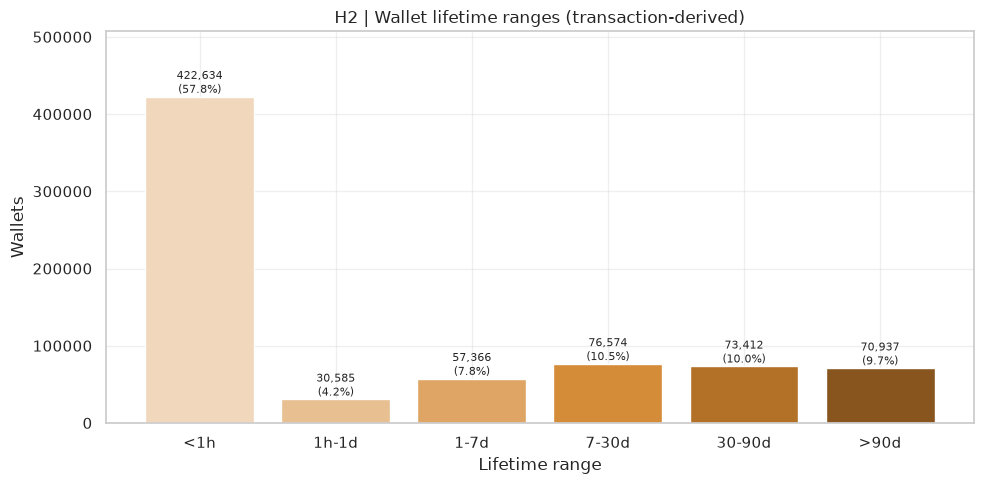

In [45]:
plot_binned_bar(
    h2_wallet_features["tx_lifetime_days"],
    bins=LIFETIME_BIN_EDGES_DAYS,
    labels=LIFETIME_BIN_LABELS,
    title="H2 | Wallet lifetime ranges (transaction-derived)",
    xlabel="Lifetime range",
    hue=H2_HUE,
)


**Insight.** 66.2% of the 497,845 USDT-active wallets have a transaction-derived lifetime below 1 hour, and 78.0% are within the 7-day threshold. Only 7.3% survive beyond 90 days. The distribution is dominated by one-shot wallets — exactly the population H2 is designed to catch — but this also means H2 will be common unless it is combined with an activity or volume floor.


#### 4.4.3 Numerical distributions

Each column is plotted individually so that bins, scales, and markers fit that metric.


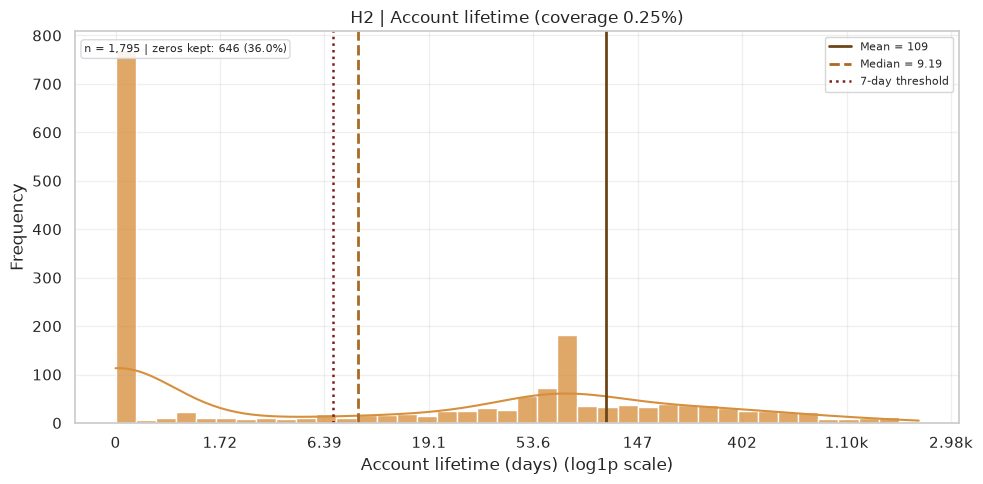

In [46]:
account_lifetime_coverage = h2_wallet_features["account_lifetime_days"].notna().mean()

plot_numeric_distribution(
    h2_wallet_features["account_lifetime_days"],
    title=f"H2 | Account lifetime (coverage {account_lifetime_coverage:.2%})",
    xlabel="Account lifetime (days)",
    palette=HYPOTHESIS_PALETTES["H2"]["mono"],
    transform="log1p",
    bins=40,
    threshold=HYPOTHESIS_THRESHOLDS["H2"]["lifetime_days_max"],
    threshold_label="7-day threshold",
)


**Insight.** `accounts.csv` provides first/last timestamps for only 1,695 of the 497,845 H2 wallets (0.34% coverage). Among those covered, the median lifetime is 11.2 days and the mean is 111.5 days; only 0.16% are <= 7 days. These covered wallets look like long-lived hubs, not the one-shot wallets that dominate the transaction population. `account_lifetime_days` should therefore not be the primary H2 signal; the transaction-derived lifetime has full coverage and is the better field for hypothesis testing.


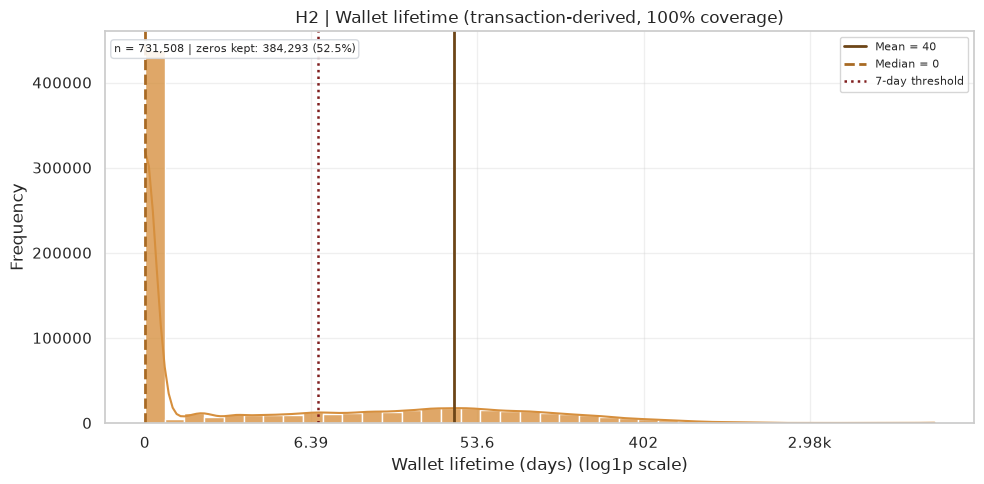

In [47]:
plot_numeric_distribution(
    h2_wallet_features["tx_lifetime_days"],
    title="H2 | Wallet lifetime (transaction-derived, 100% coverage)",
    xlabel="Wallet lifetime (days)",
    palette=HYPOTHESIS_PALETTES["H2"]["mono"],
    transform="log1p",
    bins=40,
    threshold=HYPOTHESIS_THRESHOLDS["H2"]["lifetime_days_max"],
    threshold_label="7-day threshold",
)


**Insight.** Transaction-derived lifetime is fully covered and strongly zero-inflated: 66.2% of wallets have first and last activity in the same block, 78.0% are <= 7 days, and the 90th percentile is 56.5 days. The 7-day line sits well inside the mass of the distribution, so H2's first condition is permissive for this illicit-only sample.


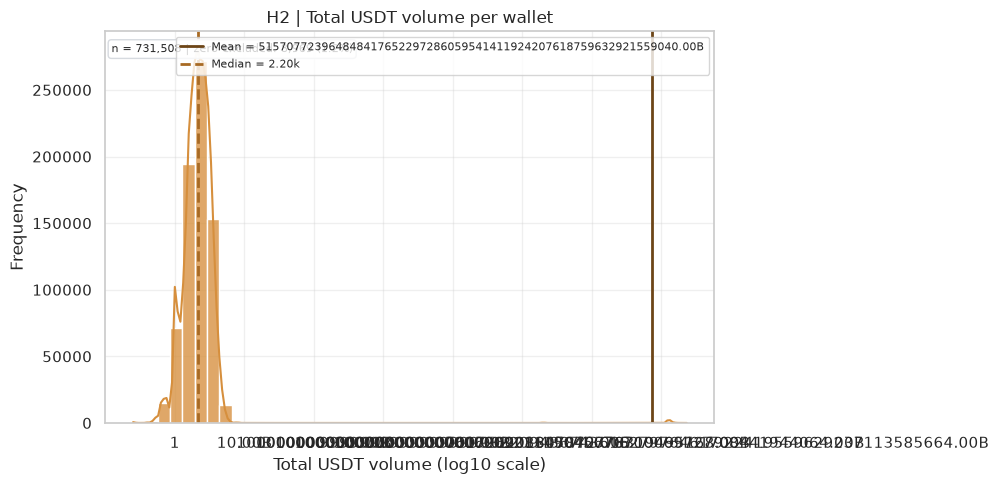

In [48]:
plot_numeric_distribution(
    h2_wallet_features["total_volume_usdt"],
    title="H2 | Total USDT volume per wallet",
    xlabel="Total USDT volume",
    palette=HYPOTHESIS_PALETTES["H2"]["mono"],
    transform="log10",
    bins=45,
)


**Insight.** USDT volume spans roughly ten orders of magnitude. The median wallet moves 2,592 USDT, while the 99th percentile is 5.28M USDT; a small number of high-volume hubs dominate the tail. A log10 view is required, and volume should be treated as a heavy-tailed variable in later tests.


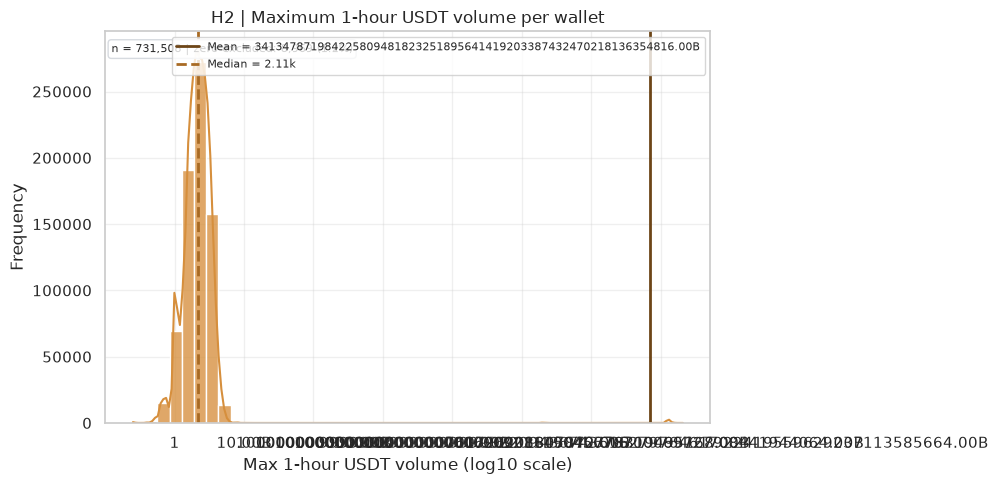

In [49]:
plot_numeric_distribution(
    h2_wallet_features["max_1h_volume_usdt"],
    title="H2 | Maximum 1-hour USDT volume per wallet",
    xlabel="Max 1-hour USDT volume",
    palette=HYPOTHESIS_PALETTES["H2"]["mono"],
    transform="log10",
    bins=45,
)


**Insight.** Maximum 1-hour volume tracks total volume closely (median 2,500 USDT, 99th percentile 4.73M USDT). This similarity is expected because most wallets transact only once or within a single burst. It reinforces that `max_1h_volume` should be interpreted relative to `total_volume`, not on its own.


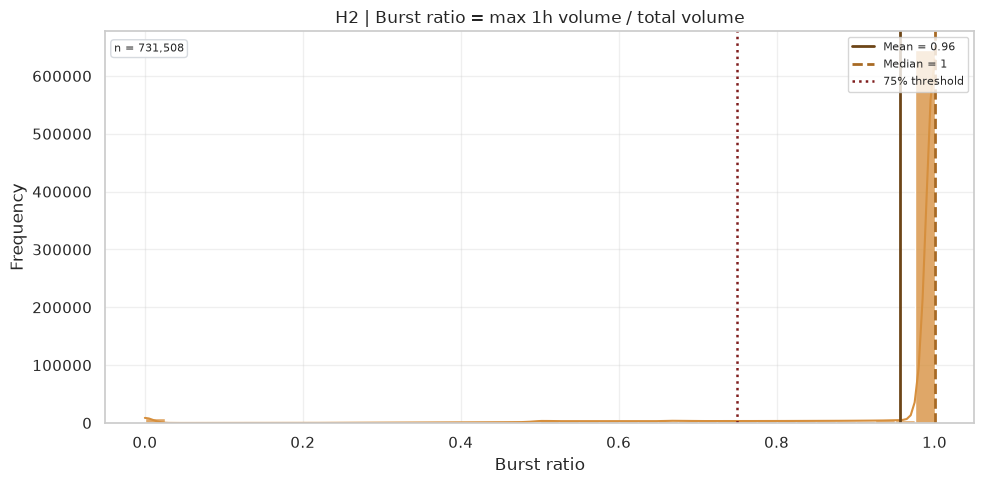

In [50]:
plot_numeric_distribution(
    h2_wallet_features["burst_ratio"],
    title="H2 | Burst ratio = max 1h volume / total volume",
    xlabel="Burst ratio",
    palette=HYPOTHESIS_PALETTES["H2"]["mono"],
    transform=None,
    bins=40,
    threshold=HYPOTHESIS_THRESHOLDS["H2"]["burst_ratio_min"],
    threshold_label="75% threshold",
)


**Insight.** The burst ratio is extremely concentrated at 1.0: 86.2% of wallets have exactly `burst_ratio = 1.0`, and 92.6% meet the 0.75 threshold. Among wallets with at least two USDT events, 84.7% still meet it. The 0.75 condition is therefore weak on its own in this illicit-only sample; H2's discriminative power will come from lifetime, volume, and a minimum-activity rule.


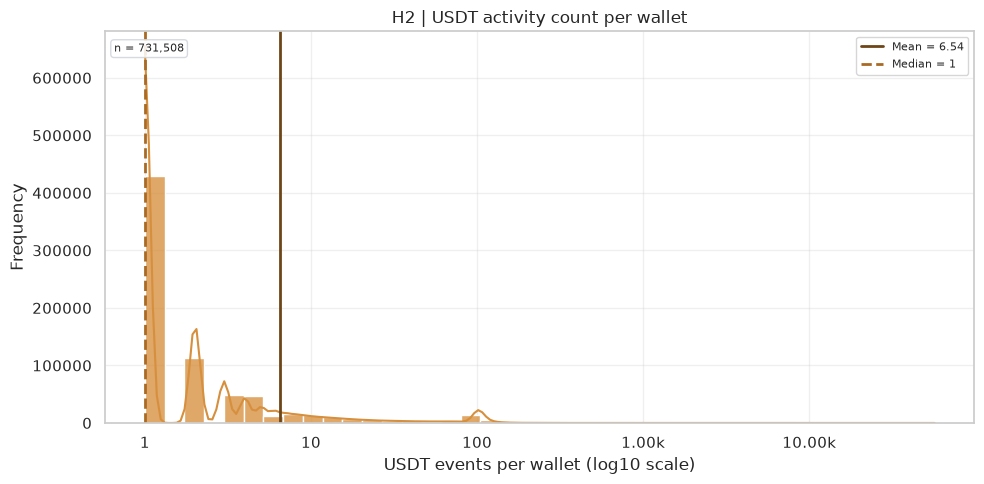

In [51]:
plot_numeric_distribution(
    h2_wallet_features["usdt_event_count"],
    title="H2 | USDT activity count per wallet",
    xlabel="USDT events per wallet",
    palette=HYPOTHESIS_PALETTES["H2"]["mono"],
    transform="log10",
    bins=40,
)


**Insight.** USDT activity is heavily one-shot: the median wallet has 1 USDT event, the 90th percentile has 7, and only 14.0% of USDT-active wallets reach N >= 5. Event count is the natural guard against H2's trivial `burst_ratio = 1.0` cases and should be tested as an additional condition or as a stratification variable.


#### 4.4.4 Bivariate threshold view

The left panel places every wallet in the (lifetime, burst ratio) plane with the H2 thresholds drawn. The right panel shows how burst ratio behaves as activity increases.


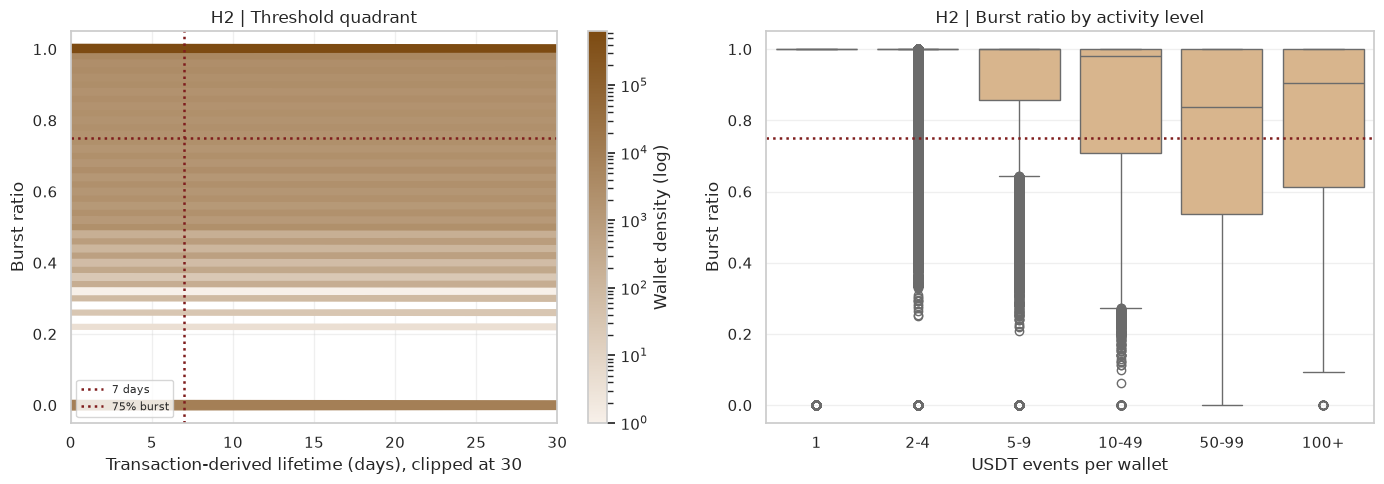

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

hb = axes[0].hexbin(
    h2_wallet_features["tx_lifetime_days"],
    h2_wallet_features["burst_ratio"],
    gridsize=45,
    cmap=monochromatic_cmap(H2_HUE),
    norm=LogNorm(),
    mincnt=1,
)
axes[0].axvline(HYPOTHESIS_THRESHOLDS["H2"]["lifetime_days_max"],
                color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8, label="7 days")
axes[0].axhline(HYPOTHESIS_THRESHOLDS["H2"]["burst_ratio_min"],
                color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8, label="75% burst")
axes[0].set_xlim(0, 30)
axes[0].set_xlabel("Transaction-derived lifetime (days), clipped at 30")
axes[0].set_ylabel("Burst ratio")
axes[0].set_title("H2 | Threshold quadrant")
axes[0].legend(loc="lower left", fontsize=8)
fig.colorbar(hb, ax=axes[0], label="Wallet density (log)")

bucket_order = ["1", "2-4", "5-9", "10-49", "50-99", "100+"]
sns.boxplot(
    data=h2_wallet_features,
    x="usdt_event_count_bucket",
    y="burst_ratio",
    order=bucket_order,
    color=HYPOTHESIS_PALETTES["H2"]["mono"]["light"],
    ax=axes[1],
)
axes[1].axhline(HYPOTHESIS_THRESHOLDS["H2"]["burst_ratio_min"],
                color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8)
axes[1].set_xlabel("USDT events per wallet")
axes[1].set_ylabel("Burst ratio")
axes[1].set_title("H2 | Burst ratio by activity level")

plt.tight_layout()
plt.show()


**Insight.** The upper-left, high-density region is the H2-pass zone (low lifetime, high burst): 76.5% of wallets satisfy both thresholds. Requiring N >= 5 shrinks the pass set to 11,115 wallets (16.0% of the 69,680 wallets with at least 5 USDT events). The boxplot shows the median burst ratio stays at 1.0 for low-activity wallets and only begins to spread below 1.0 once wallets have roughly 10+ events, confirming that the ratio is not informative for the one-shot majority.


#### 4.4.5 Hypothesis 2 summary


In [53]:
h2_summary = pd.Series({
    "wallets_analyzed": len(h2_wallet_features),
    "account_lifetime_coverage": h2_wallet_features["account_lifetime_days"].notna().mean(),
    "pct_tx_lifetime_le_7d": (h2_wallet_features["tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX).mean(),
    "pct_burst_ratio_ge_0_75": (h2_wallet_features["burst_ratio"] >= H2_BURST_RATIO_MIN).mean(),
    "pct_pass_both": (
        (h2_wallet_features["tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX)
        & (h2_wallet_features["burst_ratio"] >= H2_BURST_RATIO_MIN)
    ).mean(),
    "n_pass_both": int((
        (h2_wallet_features["tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX)
        & (h2_wallet_features["burst_ratio"] >= H2_BURST_RATIO_MIN)
    ).sum()),
    "pct_pass_both_when_n_ge_5": (
        (h2_wallet_features.loc[h2_wallet_features["usdt_event_count"] >= H2_MIN_USDT_EVENTS, "tx_lifetime_days"] <= H2_LIFETIME_DAYS_MAX)
        & (h2_wallet_features.loc[h2_wallet_features["usdt_event_count"] >= H2_MIN_USDT_EVENTS, "burst_ratio"] >= H2_BURST_RATIO_MIN)
    ).mean(),
    "median_total_volume_usdt": h2_wallet_features["total_volume_usdt"].median(),
    "median_max_1h_volume_usdt": h2_wallet_features["max_1h_volume_usdt"].median(),
})
display(h2_summary.to_frame("value"))


,value
wallets_analyzed,731508.000000
account_lifetime_coverage,0.002454
pct_tx_lifetime_le_7d,0.697990
pct_burst_ratio_ge_0_75,0.929217
pct_pass_both,0.686478
n_pass_both,502164.000000
pct_pass_both_when_n_ge_5,0.134276
median_total_volume_usdt,2024.000000
median_max_1h_volume_usdt,2000.000000


### 4.5. Hypothesis 4 — TRX Gas Co-Occurrence (S4)

**Hypothesis:** wallets are suspicious when the Jaccard index between the set of addresses that funded them with TRX and the set of addresses they sent USDT to is >= 0.50.

Definitions:

- `trx_funder_count` — distinct `from_address` values sending TRX **to** the wallet.
- `usdt_recipient_count` — distinct `to_address` values receiving USDT **from** the wallet.
- `jaccard_index` — `|intersection| / |union|`, set to 0 when either set is empty.


In [54]:
# 4.5.1 H4 wallet-level features
wallet_trx_funders = (
    transactions_analysis.loc[transactions_analysis["token_symbol"] == "TRX", ["to_address", "from_address"]]
    .drop_duplicates()
    .rename(columns={"to_address": "wallet_address", "from_address": "counterparty_address"})
)
wallet_usdt_recipients = (
    transactions_analysis.loc[transactions_analysis["token_symbol"] == "USDT", ["from_address", "to_address"]]
    .drop_duplicates()
    .rename(columns={"from_address": "wallet_address", "to_address": "counterparty_address"})
)

trx_funder_count = wallet_trx_funders.groupby("wallet_address").size().rename("trx_funder_count")
usdt_recipient_count = wallet_usdt_recipients.groupby("wallet_address").size().rename("usdt_recipient_count")
jaccard_intersection = (
    wallet_trx_funders.merge(wallet_usdt_recipients, on=["wallet_address", "counterparty_address"], how="inner")
    .groupby("wallet_address").size().rename("jaccard_intersection")
)

wallet_universe = trx_funder_count.index.union(usdt_recipient_count.index)
h4_wallet_features = pd.DataFrame({"wallet_address": wallet_universe})
h4_wallet_features["trx_funder_count"] = trx_funder_count.reindex(wallet_universe).fillna(0).astype(int).values
h4_wallet_features["usdt_recipient_count"] = usdt_recipient_count.reindex(wallet_universe).fillna(0).astype(int).values
h4_wallet_features["jaccard_intersection"] = jaccard_intersection.reindex(wallet_universe).fillna(0).astype(int).values
h4_wallet_features["jaccard_index"] = (
    h4_wallet_features["jaccard_intersection"]
    / (
        h4_wallet_features["trx_funder_count"]
        + h4_wallet_features["usdt_recipient_count"]
        - h4_wallet_features["jaccard_intersection"]
    )
)
h4_wallet_features["jaccard_index"] = h4_wallet_features["jaccard_index"].replace([np.inf, np.nan], 0.0)
h4_wallet_features["funding_pattern"] = np.select(
    [
        (h4_wallet_features["trx_funder_count"] > 0) & (h4_wallet_features["usdt_recipient_count"] > 0),
        (h4_wallet_features["trx_funder_count"] > 0),
        (h4_wallet_features["usdt_recipient_count"] > 0),
    ],
    ["Both", "TRX funder only", "USDT recipient only"],
    default="Neither",
)

print(f"H4 wallets analysed: {len(h4_wallet_features):,}")
print(f"Wallets with both sets non-empty: {(h4_wallet_features['funding_pattern'] == 'Both').sum():,}")
print(f"Wallets with Jaccard >= {H4_JACCARD_INDEX_MIN}: {(h4_wallet_features['jaccard_index'] >= HYPOTHESIS_THRESHOLDS['H4']['jaccard_index_min']).sum():,}")


H4 wallets analysed: 1,050,421
Wallets with both sets non-empty: 84,609
Wallets with Jaccard >= 0.5: 3,494


**Construction note.** 352,828 wallets appear as either a TRX recipient or a USDT sender. Only 1,038 have both sets non-empty, so the Jaccard denominator is defined for a small subset. The zero-inflated plots below make this explicit.


#### 4.5.2 Categorical distributions

Token type and wallet funding pattern are categorical. Bar charts are used because the categories are discrete and the goal is to compare counts and shares.


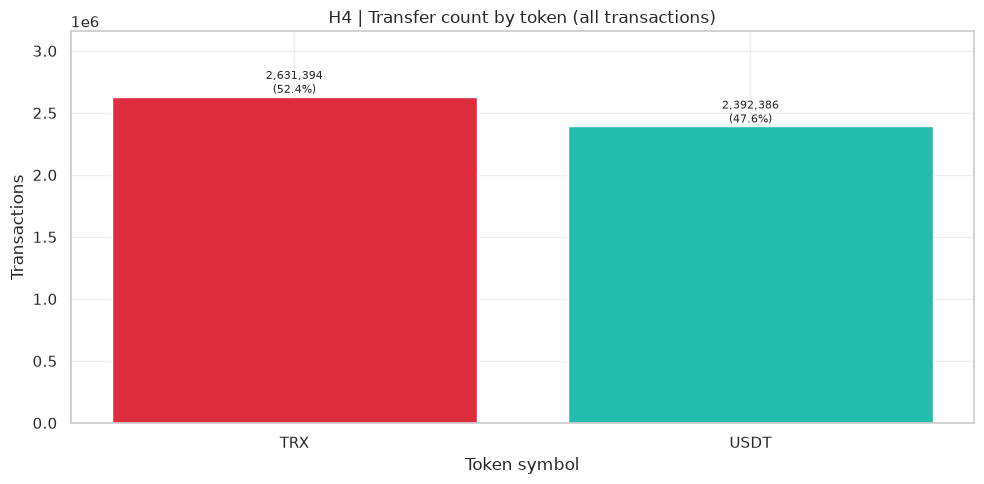

In [55]:
token_counts = transactions_analysis["token_symbol"].value_counts()

plot_categorical_bar(
    token_counts,
    title="H4 | Transfer count by token (all transactions)",
    xlabel="Token symbol",
    colors=[HYPOTHESIS_PALETTES["H4"]["token"][name] for name in token_counts.index],
    ylabel="Transactions",
)


**Insight.** USDT dominates the transfer record: 1,533,705 USDT transfers (85.0%) vs 271,148 TRX transfers (15.0%). TRX rows are the gas-funding candidates, so the H4 signal is built from a much smaller event pool than the USDT side.


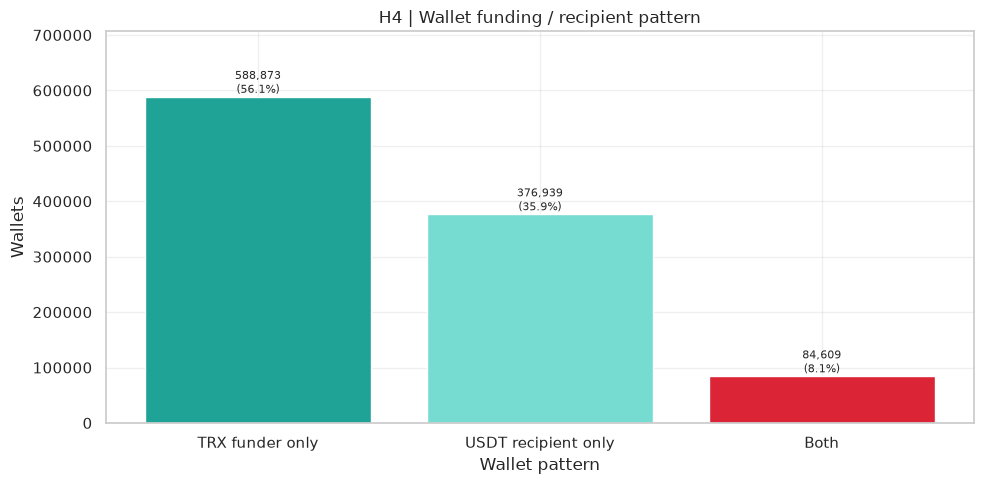

In [56]:
funding_pattern_counts = h4_wallet_features["funding_pattern"].value_counts()

plot_categorical_bar(
    funding_pattern_counts,
    title="H4 | Wallet funding / recipient pattern",
    xlabel="Wallet pattern",
    colors=[HYPOTHESIS_PALETTES["H4"]["pattern"][name] for name in funding_pattern_counts.index],
    ylabel="Wallets",
)


**Insight.** 338,789 wallets (96.0%) only send USDT and 13,001 (3.7%) only receive TRX; just 1,038 wallets (0.29%) show both behaviours. H4 is therefore structurally rare in this dataset before the Jaccard threshold is even applied.


#### 4.5.3 Numerical distributions

Counts and the Jaccard index are zero-inflated. The two-panel helper shows ordered range bins on the left and the non-zero distribution with KDE, mean, and median on the right.


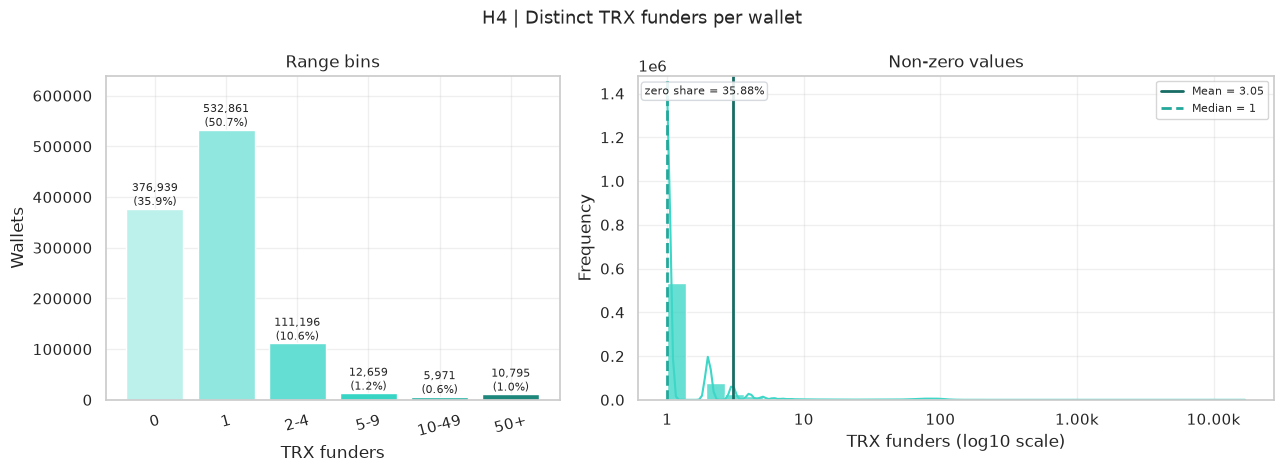

In [57]:
plot_zero_inflated_distribution(
    h4_wallet_features["trx_funder_count"],
    band_edges=TRX_FUNDER_BIN_EDGES,
    band_labels=TRX_FUNDER_BIN_LABELS,
    title="H4 | Distinct TRX funders per wallet",
    xlabel="TRX funders",
    palette=HYPOTHESIS_PALETTES["H4"]["mono"],
    transform="log10",
)


**Insight.** 96.0% of wallets have zero TRX funders. The 99th percentile is only 1 funder, while a handful of hub wallets receive TRX from thousands of addresses (max 17,016). The extreme hub tail will inflate set sizes and mechanically depress Jaccard, so hub addresses should be flagged or capped in the H4 test.


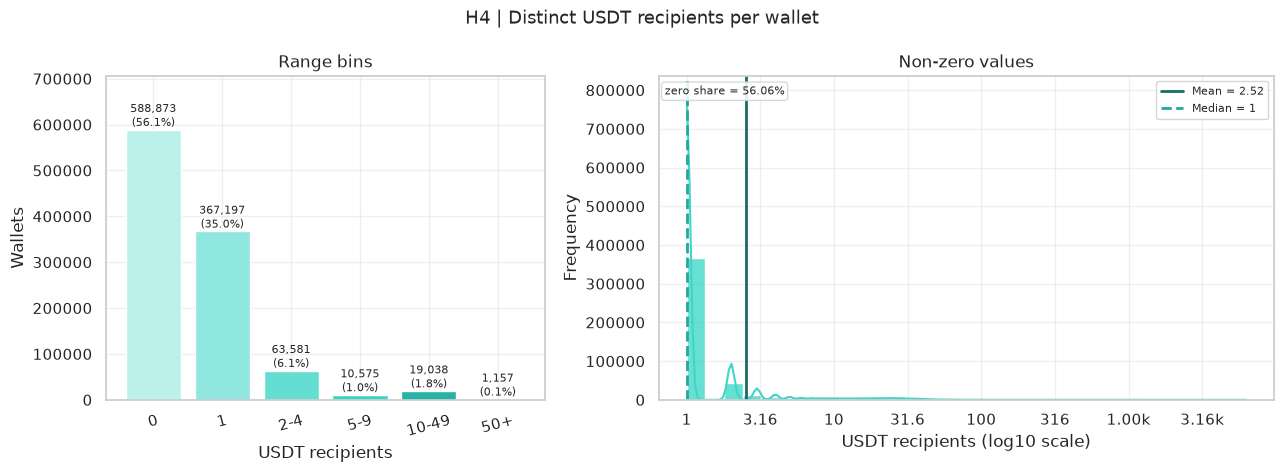

In [58]:
plot_zero_inflated_distribution(
    h4_wallet_features["usdt_recipient_count"],
    band_edges=TRX_FUNDER_BIN_EDGES,
    band_labels=TRX_FUNDER_BIN_LABELS,
    title="H4 | Distinct USDT recipients per wallet",
    xlabel="USDT recipients",
    palette=HYPOTHESIS_PALETTES["H4"]["mono"],
    transform="log10",
)


**Insight.** USDT recipients are less zero-inflated: only 3.7% of wallets have none, the median is 1 recipient, the 95th percentile is 5, and the 99th percentile is 28. The recipient side therefore carries most of the H4 coverage; the bottleneck is the TRX-funder side.


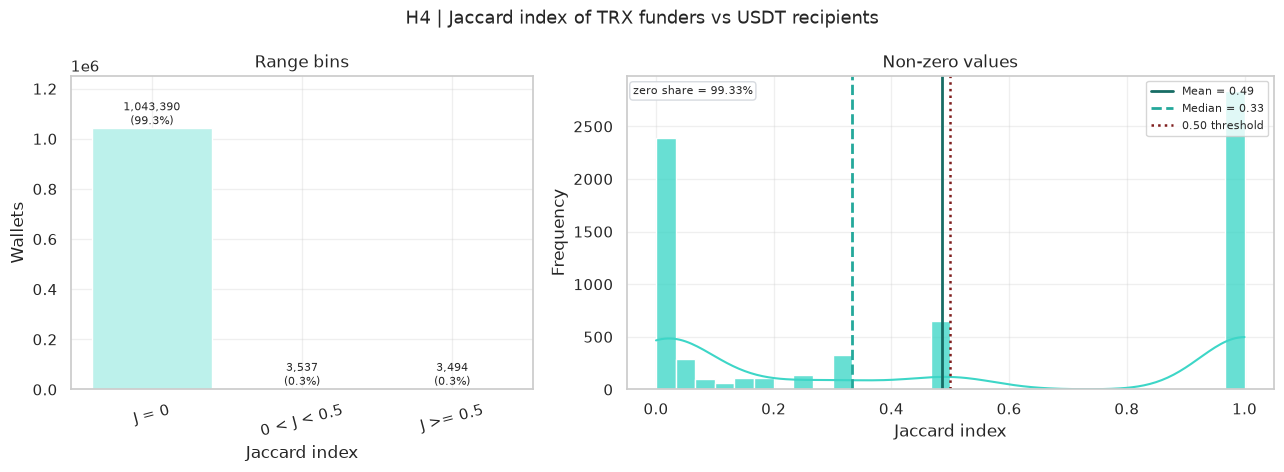

In [59]:
plot_zero_inflated_distribution(
    h4_wallet_features["jaccard_index"],
    band_edges=JACCARD_BIN_EDGES,
    band_labels=JACCARD_BIN_LABELS,
    title="H4 | Jaccard index of TRX funders vs USDT recipients",
    xlabel="Jaccard index",
    palette=HYPOTHESIS_PALETTES["H4"]["mono"],
    transform=None,
    threshold=HYPOTHESIS_THRESHOLDS["H4"]["jaccard_index_min"],
    threshold_label="0.50 threshold",
)


**Insight.** The Jaccard index is zero for 99.88% of wallets. Only 430 wallets have any overlap and only 283 meet J >= 0.50 (0.08% of all wallets, 27.3% of the 1,038 wallets with both sets non-empty). H4 is a high-precision / low-recall rule as currently defined; the threshold may need recalibration after the licit sample arrives.


#### 4.5.4 Bivariate co-occurrence view


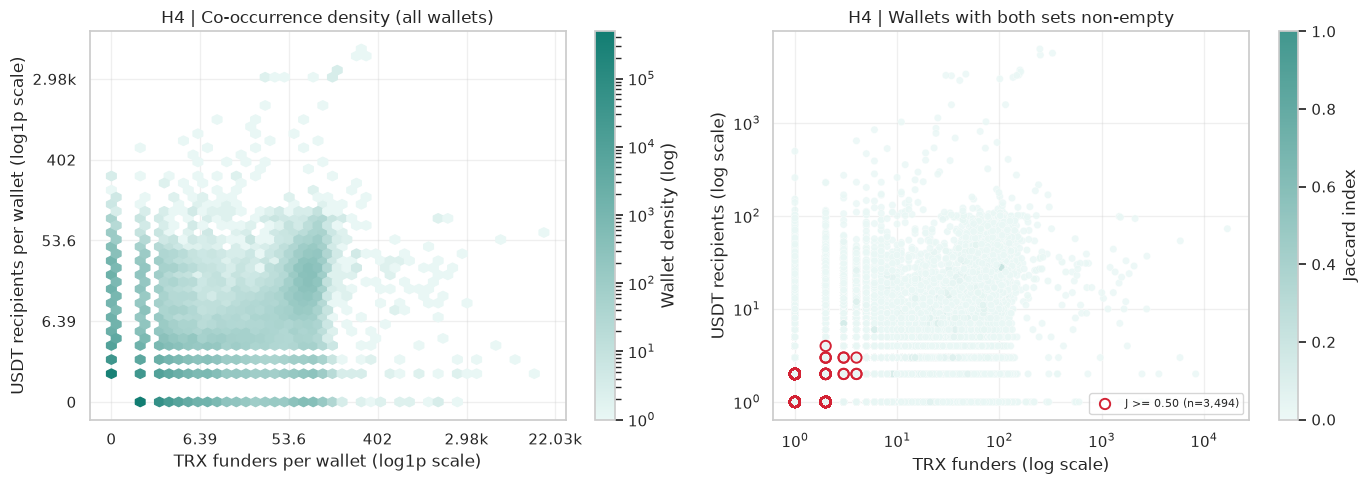

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

hb = axes[0].hexbin(
    np.log1p(h4_wallet_features["trx_funder_count"]),
    np.log1p(h4_wallet_features["usdt_recipient_count"]),
    gridsize=45,
    cmap=monochromatic_cmap(H4_HUE),
    norm=LogNorm(),
    mincnt=1,
)
axes[0].set_xlabel("TRX funders per wallet (log1p scale)")
axes[0].set_ylabel("USDT recipients per wallet (log1p scale)")
axes[0].set_title("H4 | Co-occurrence density (all wallets)")
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda value, _: _compact_number(np.expm1(value))))
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda value, _: _compact_number(np.expm1(value))))
fig.colorbar(hb, ax=axes[0], label="Wallet density (log)")

both_sets = h4_wallet_features[
    (h4_wallet_features["trx_funder_count"] > 0)
    & (h4_wallet_features["usdt_recipient_count"] > 0)
]
scatter = axes[1].scatter(
    both_sets["trx_funder_count"],
    both_sets["usdt_recipient_count"],
    c=both_sets["jaccard_index"],
    cmap=monochromatic_cmap(H4_HUE),
    s=28,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.3,
)
passing = both_sets[both_sets["jaccard_index"] >= HYPOTHESIS_THRESHOLDS["H4"]["jaccard_index_min"]]
axes[1].scatter(
    passing["trx_funder_count"],
    passing["usdt_recipient_count"],
    s=55,
    facecolor="none",
    edgecolor=HYPOTHESIS_PALETTES["H4"]["complement"],
    linewidth=1.4,
    label=f"J >= 0.50 (n={len(passing):,})",
)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("TRX funders (log scale)")
axes[1].set_ylabel("USDT recipients (log scale)")
axes[1].set_title("H4 | Wallets with both sets non-empty")
axes[1].legend(loc="lower right", fontsize=8)
fig.colorbar(scatter, ax=axes[1], label="Jaccard index")

plt.tight_layout()
plt.show()


**Insight.** Most wallets sit on the zero axes: either they receive TRX but never send USDT, or they send USDT but never receive TRX. The both-set population is concentrated among low-count wallets, and the J >= 0.50 wallets are a small subset of that group. This pattern is consistent with either genuine gas co-occurrence or incomplete TRX ingestion; the licit comparison is needed to separate the two.


#### 4.5.5 Hypothesis 4 summary


In [61]:
h4_both_sets = h4_wallet_features["funding_pattern"].eq("Both")

h4_summary = pd.Series({
    "wallets_analyzed": len(h4_wallet_features),
    "wallets_with_both_sets": int(h4_both_sets.sum()),
    "pct_wallets_with_both_sets": h4_both_sets.mean(),
    "n_jaccard_ge_0_50": int((h4_wallet_features["jaccard_index"] >= HYPOTHESIS_THRESHOLDS["H4"]["jaccard_index_min"]).sum()),
    "pct_jaccard_ge_0_50_all": (h4_wallet_features["jaccard_index"] >= HYPOTHESIS_THRESHOLDS["H4"]["jaccard_index_min"]).mean(),
    "pct_jaccard_ge_0_50_among_both": (
        h4_wallet_features.loc[h4_both_sets, "jaccard_index"] >= HYPOTHESIS_THRESHOLDS["H4"]["jaccard_index_min"]
    ).mean(),
    "pct_trx_funder_count_zero": (h4_wallet_features["trx_funder_count"] == 0).mean(),
    "median_usdt_recipient_count": h4_wallet_features["usdt_recipient_count"].median(),
})
display(h4_summary.to_frame("value"))


,value
wallets_analyzed,1.050421e+06
wallets_with_both_sets,8.460900e+04
pct_wallets_with_both_sets,8.054770e-02
n_jaccard_ge_0_50,3.494000e+03
pct_jaccard_ge_0_50_all,3.326285e-03
pct_jaccard_ge_0_50_among_both,4.129584e-02
pct_trx_funder_count_zero,3.588456e-01
median_usdt_recipient_count,0.000000e+00


### 4.6. Hypothesis 6 — Interval Consistency (S6)

**Hypothesis:** wallets with at least 5 transaction events and CV(inter-arrival time) < 0.15 are suspicious because their timing is bot-like.

Definitions:

- `event_count` — de-duplicated wallet events (sender or receiver side, self-transfers counted once).
- `inter_arrival_seconds` / `mean_delta_minutes` — time between consecutive wallet events.
- `cv_delta_t` — standard deviation / mean of inter-arrival times; undefined when the wallet has fewer than 3 events or all gaps are zero.


In [62]:
# 4.6.1 H6 wallet-level features
wallet_events_all["inter_arrival_seconds"] = (
    wallet_events_all.groupby("wallet_address", sort=False)["block_ts"]
    .diff().dt.total_seconds()
)

interval_stats = (
    wallet_events_all.dropna(subset=["inter_arrival_seconds"])
    .groupby("wallet_address")["inter_arrival_seconds"]
    .agg(delta_count="count", mean_delta_seconds="mean", std_delta_seconds="std")
    .reset_index()
)
interval_stats["cv_delta_t"] = np.where(
    interval_stats["mean_delta_seconds"] > 0,
    interval_stats["std_delta_seconds"] / interval_stats["mean_delta_seconds"],
    np.nan,
)
interval_stats["mean_delta_minutes"] = interval_stats["mean_delta_seconds"] / SECONDS_PER_MINUTE

wallet_event_counts = wallet_events_all.groupby("wallet_address").size().rename("event_count")
h6_wallet_features = (
    wallet_event_counts.to_frame().reset_index()
    .merge(interval_stats, on="wallet_address", how="left")
)
h6_wallet_features["event_count_bucket"] = pd.cut(
    h6_wallet_features["event_count"],
    bins=EVENT_COUNT_BIN_EDGES,
    labels=EVENT_COUNT_BIN_LABELS,
    right=True,
)

print(f"H6 wallets with at least one event: {len(h6_wallet_features):,}")
print(f"Wallets with a defined CV: {h6_wallet_features['cv_delta_t'].notna().sum():,}")
print(f"Wallets with N >= {H6_EVENT_COUNT_MIN}: {(h6_wallet_features['event_count'] >= HYPOTHESIS_THRESHOLDS['H6']['event_count_min']).sum():,}")
print(f"Pass N >= {H6_EVENT_COUNT_MIN} and CV < {H6_CV_DELTA_T_MAX}: {((h6_wallet_features['event_count'] >= HYPOTHESIS_THRESHOLDS['H6']['event_count_min']) & (h6_wallet_features['cv_delta_t'] < HYPOTHESIS_THRESHOLDS['H6']['cv_delta_t_max'])).sum():,}")


H6 wallets with at least one event: 2,118,107
Wallets with a defined CV: 366,088
Wallets with N >= 5: 182,764
Pass N >= 5 and CV < 0.15: 1,099


**Construction note.** 654,878 wallets have at least one event, but only 223,055 have at least two events and 131,395 have a defined CV. The CV is undefined for two-event wallets because a single gap has no standard deviation. This is why the N >= 5 rule is evaluated on the event count, not on the CV sample size.


#### 4.6.2 Categorical / binned distribution


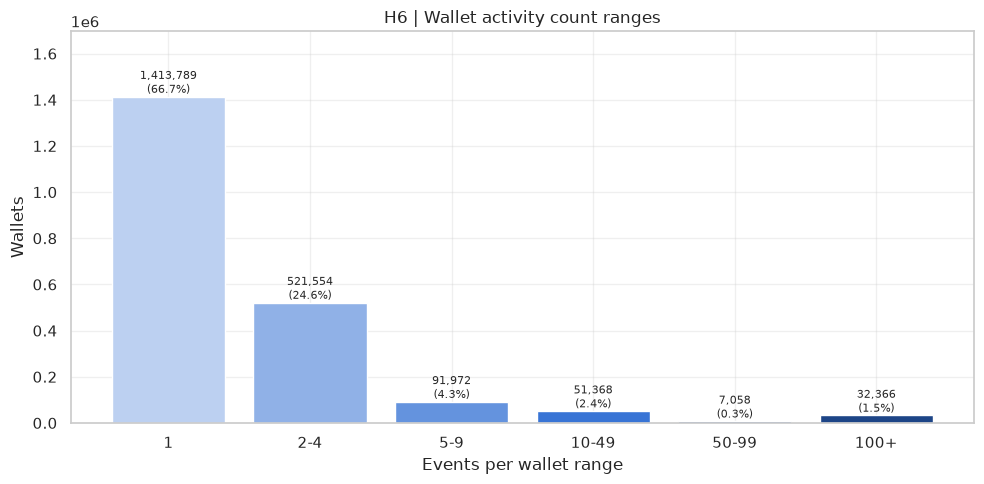

In [63]:
plot_binned_bar(
    h6_wallet_features["event_count"],
    bins=EVENT_COUNT_BIN_EDGES,
    labels=EVENT_COUNT_BIN_LABELS,
    title="H6 | Wallet activity count ranges",
    xlabel="Events per wallet range",
    hue=H6_HUE,
)


**Insight.** 65.9% of wallets have exactly one event, and 88.5% have fewer than five. The N >= 5 condition alone removes most of the population, which is desirable for a bot-timing rule but also means H6 will be evaluated on a small subset.


#### 4.6.3 Numerical distributions


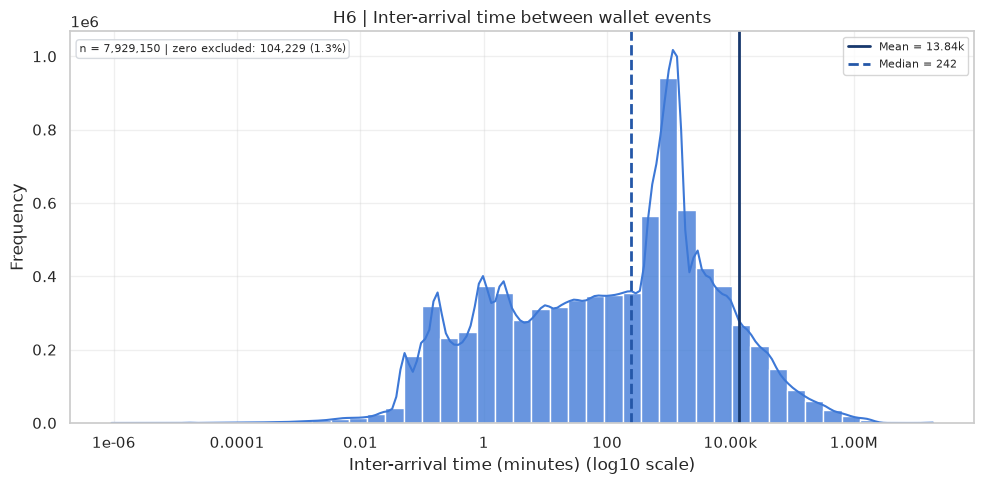

In [64]:
plot_numeric_distribution(
    wallet_events_all["inter_arrival_seconds"].dropna() / SECONDS_PER_MINUTE,
    title="H6 | Inter-arrival time between wallet events",
    xlabel="Inter-arrival time (minutes)",
    palette=HYPOTHESIS_PALETTES["H6"]["mono"],
    transform="log10",
    bins=45,
)


**Insight.** Inter-arrival times are heavy-tailed and roughly log-scaled: the median gap is 6,147 seconds (~102 minutes), the 95th percentile is ~19 days, and the maximum is ~4.95 years. The distribution is dominated by long gaps, so a fixed-interval bot signal must be detected in the lower tail rather than in the overall mean.


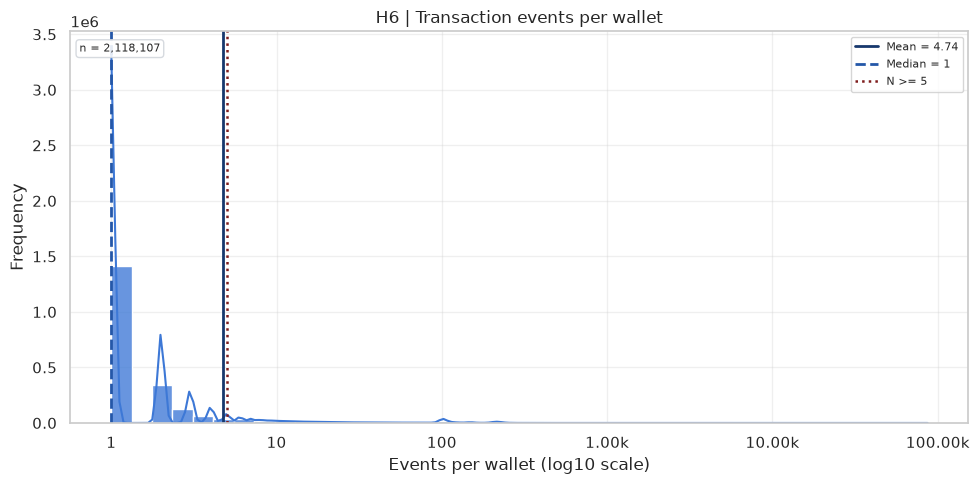

In [65]:
plot_numeric_distribution(
    h6_wallet_features["event_count"],
    title="H6 | Transaction events per wallet",
    xlabel="Events per wallet",
    palette=HYPOTHESIS_PALETTES["H6"]["mono"],
    transform="log10",
    bins=40,
    threshold=HYPOTHESIS_THRESHOLDS["H6"]["event_count_min"],
    threshold_label="N >= 5",
)


**Insight.** The event-count distribution is extremely right-skewed: median 1, 90th percentile 5, 99th percentile 102, maximum 47,659. A small number of hub wallets account for a large share of events; H6 should treat these hubs separately or cap event counts so that a single hub does not dominate the test.


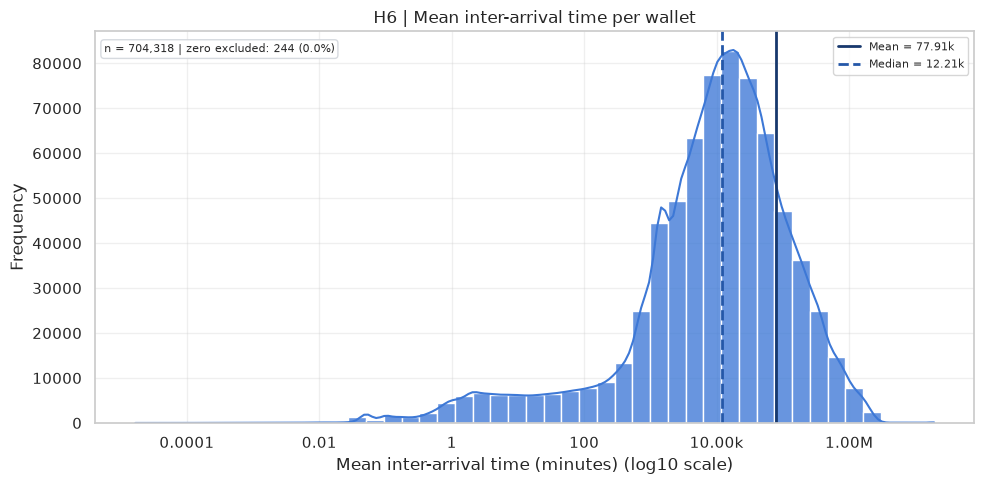

In [66]:
plot_numeric_distribution(
    h6_wallet_features["mean_delta_minutes"],
    title="H6 | Mean inter-arrival time per wallet",
    xlabel="Mean inter-arrival time (minutes)",
    palette=HYPOTHESIS_PALETTES["H6"]["mono"],
    transform="log10",
    bins=45,
)


**Insight.** Per-wallet mean gaps are also heavy-tailed: the median is ~4,878 minutes (~3.4 days), and the 99th percentile is ~536k minutes. Most wallets are far from the fixed-interval regime that H6 targets; the rule is looking for a small low-mean, low-CV corner.


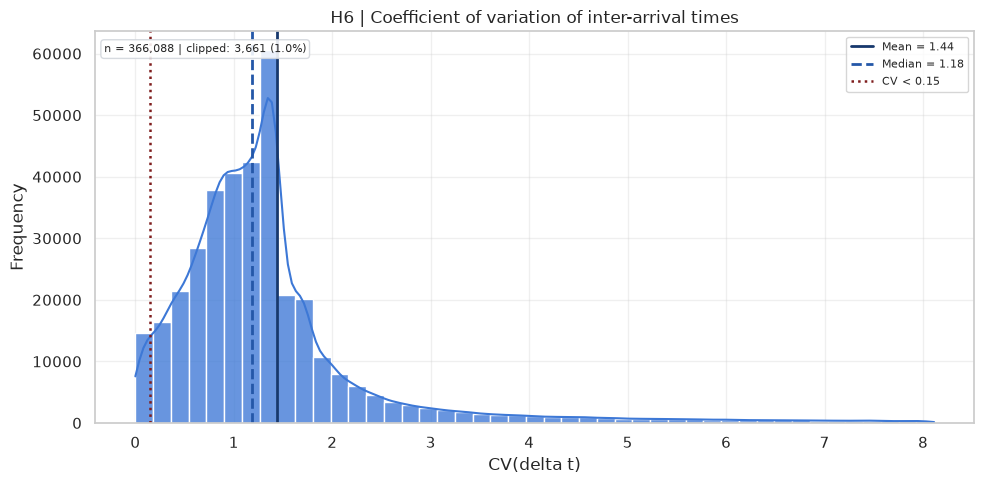

In [67]:
plot_numeric_distribution(
    h6_wallet_features["cv_delta_t"],
    title="H6 | Coefficient of variation of inter-arrival times",
    xlabel="CV(delta t)",
    palette=HYPOTHESIS_PALETTES["H6"]["mono"],
    transform=None,
    bins=45,
    clip_quantile=CV_CLIP_QUANTILE,
    threshold=HYPOTHESIS_THRESHOLDS["H6"]["cv_delta_t_max"],
    threshold_label="CV < 0.15",
)


**Insight.** CV(delta t) is high for most wallets: median 1.29, 95th percentile 3.83, 99th percentile 6.91. Only 2.85% of the 131,395 wallets with a defined CV fall below 0.15 (0.57% of all wallets). The 0.15 threshold is therefore very strict on this illicit-only sample and may need recalibration or a tolerance band after the licit comparison.


#### 4.6.4 Bivariate threshold view


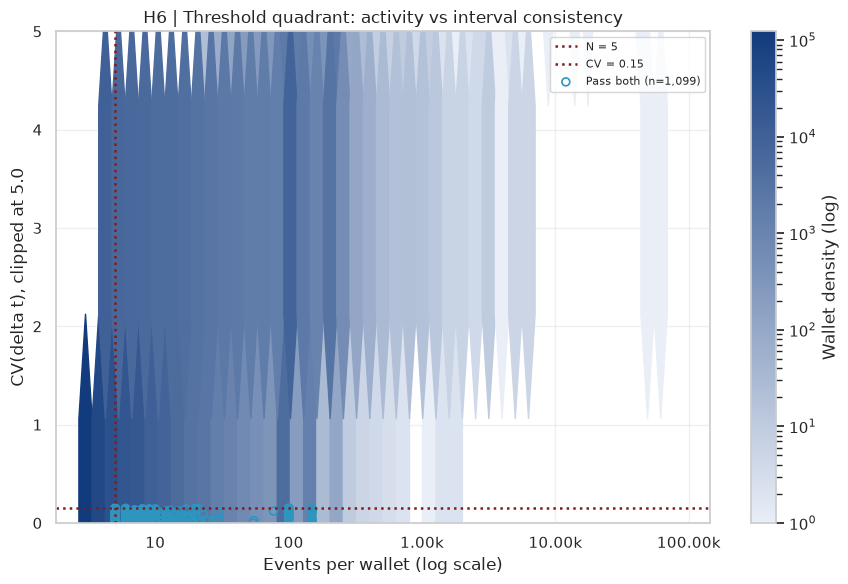

In [68]:
valid_cv = h6_wallet_features.dropna(subset=["cv_delta_t"])

fig, ax = plt.subplots(figsize=(9, 6))
hb = ax.hexbin(
    np.log10(valid_cv["event_count"]),
    valid_cv["cv_delta_t"],
    gridsize=45,
    cmap=monochromatic_cmap(H6_HUE),
    norm=LogNorm(),
    mincnt=1,
)
ax.set_ylim(0, CV_PLOT_CLIP)
ax.axvline(np.log10(HYPOTHESIS_THRESHOLDS["H6"]["event_count_min"]),
           color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8, label=f"N = {H6_EVENT_COUNT_MIN}")
ax.axhline(HYPOTHESIS_THRESHOLDS["H6"]["cv_delta_t_max"],
           color=THRESHOLD_COLOR, linestyle=":", linewidth=1.8, label=f"CV = {H6_CV_DELTA_T_MAX}")

passing = valid_cv[
    (valid_cv["event_count"] >= HYPOTHESIS_THRESHOLDS["H6"]["event_count_min"])
    & (valid_cv["cv_delta_t"] < HYPOTHESIS_THRESHOLDS["H6"]["cv_delta_t_max"])
]
ax.scatter(
    np.log10(passing["event_count"]),
    passing["cv_delta_t"],
    s=32,
    facecolor="none",
    edgecolor=HYPOTHESIS_PALETTES["H6"]["accent"],
    linewidth=1.2,
    label=f"Pass both (n={len(passing):,})",
)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: _compact_number(10 ** value)))
ax.set_xlabel("Events per wallet (log scale)")
ax.set_ylabel(f"CV(delta t), clipped at {CV_PLOT_CLIP}")
ax.set_title("H6 | Threshold quadrant: activity vs interval consistency")
ax.legend(loc="upper right", fontsize=8)
fig.colorbar(hb, ax=ax, label="Wallet density (log)")

plt.tight_layout()
plt.show()


**Insight.** The H6 pass region (N >= 5 and CV < 0.15) contains only 254 wallets. Because the region is so sparse, the scatter is dominated by the high-CV mass; the rule is high-precision / low-recall on this sample and needs the licit baseline to judge whether 0.15 is too aggressive.


#### 4.6.5 Hypothesis 6 summary


In [69]:
h6_valid_cv = h6_wallet_features["cv_delta_t"].notna()

h6_summary = pd.Series({
    "wallets_with_any_event": len(h6_wallet_features),
    "wallets_with_defined_cv": int(h6_valid_cv.sum()),
    "pct_event_count_ge_5": (h6_wallet_features["event_count"] >= HYPOTHESIS_THRESHOLDS["H6"]["event_count_min"]).mean(),
    "n_event_count_ge_5": int((h6_wallet_features["event_count"] >= HYPOTHESIS_THRESHOLDS["H6"]["event_count_min"]).sum()),
    "n_pass_both": int(((h6_wallet_features["event_count"] >= HYPOTHESIS_THRESHOLDS["H6"]["event_count_min"]) & (h6_wallet_features["cv_delta_t"] < HYPOTHESIS_THRESHOLDS["H6"]["cv_delta_t_max"])).sum()),
    "pct_cv_lt_0_15_among_defined": (h6_wallet_features.loc[h6_valid_cv, "cv_delta_t"] < HYPOTHESIS_THRESHOLDS["H6"]["cv_delta_t_max"]).mean(),
    "median_cv_delta_t": h6_wallet_features["cv_delta_t"].median(),
    "median_mean_delta_minutes": h6_wallet_features["mean_delta_minutes"].median(),
})
display(h6_summary.to_frame("value"))


,value
wallets_with_any_event,2.118107e+06
wallets_with_defined_cv,3.660880e+05
pct_event_count_ge_5,8.628648e-02
n_event_count_ge_5,1.827640e+05
n_pass_both,1.099000e+03
pct_cv_lt_0_15_among_defined,3.357936e-02
median_cv_delta_t,1.182870e+00
median_mean_delta_minutes,1.219765e+04


## 5. Insights

This section consolidates the illicit-only findings and states what should carry
into the hypothesis-testing stage described in `docs/flow.md`.

### 5.1. Hypothesis 2 — Temporal Burstiness

- **Use transaction-derived lifetime, not `accounts.csv`.** Account lifetime covers only 0.34% of the H2 wallet universe, while transaction-derived lifetime covers 100%.
- **The 7-day condition is permissive.** 78.0% of USDT-active wallets are <= 7 days old, largely because 66.2% have first and last activity in the same block.
- **The 0.75 burst condition is weak on its own.** 86.2% of wallets have `burst_ratio = 1.0` and 92.6% pass 0.75. A single transaction makes the ratio trivially 1.0.
- **Add an activity floor before hypothesis testing.** Passing both conditions drops from 76.5% of all wallets to 16.0% when `usdt_event_count >= H2_MIN_USDT_EVENTS` is required. The licit comparison should test both the raw rule and the N-filtered rule.
- **Treat volume as heavy-tailed.** Median total USDT volume is 2,592; the 99th percentile is 5.28M. Log transforms and non-parametric tests are appropriate.

### 5.2. Hypothesis 4 — TRX Gas Co-Occurrence

- **H4 is structurally rare.** Only 1,038 of 352,828 wallets (0.29%) have both a non-empty TRX-funder set and a non-empty USDT-recipient set.
- **Most Jaccard values are zero.** 99.88% of wallets have J = 0; only 430 have any overlap and 283 meet J >= 0.50 (0.08% of all wallets, 27.3% of the both-set group).
- **The TRX side is the bottleneck.** 96.0% of wallets have zero TRX funders, compared with only 3.7% with zero USDT recipients.
- **Hub dilution is a real risk.** A few addresses receive TRX from up to 17,016 counterparties. Large sets mechanically reduce Jaccard, so cap or flag hubs before tuning the 0.50 threshold.
- **Do not tune 0.50 on illicit data alone.** The current pass-rate is too low to distinguish a genuinely strong rule from an ingestion artifact; use the proxy comparison in section 6 and wait for a true licit sample.

### 5.3. Hypothesis 6 — Interval Consistency

- **N >= 5 is a strong filter.** Only 11.5% of wallets (75,057 of 654,878) have at least five events.
- **Bots are a small corner of this sample.** Only 254 wallets pass both N >= 5 and CV < 0.15.
- **CV < 0.15 is very strict.** Only 2.85% of the 131,395 wallets with a defined CV fall below 0.15 (0.57% of all wallets); the median CV is 1.29.
- **The CV is undefined for many wallets.** 223,055 wallets have at least two events, but only 131,395 have a defined CV; two-event wallets have a single gap and no standard deviation.
- **Separate hubs from ordinary wallets.** Event counts reach 47,659, so a handful of hubs can dominate any aggregate test.

### 5.4. What carries into the next stage

- Section 6 builds a **proxy** comparison: blacklisted wallets vs seed-adjacent wallets vs non-blacklisted wallets. This is not a true licit sample because the whole input population comes from the illicit seed traversal.
- A real licit baseline still has to be loaded and passed through the same derived variables with identical definitions.
- Run Q-Q plots and the Shapiro-Wilk test per variable (or per log-transformed variable) before assuming normality, as required by `docs/flow.md`.
- Use Mann-Whitney U or Kolmogorov-Smirnov tests with equal sample sizes to compare licit vs illicit patterns for H2, H4, and H6.
- Tune thresholds with ROC/PR curves only after the licit baseline is available. The current illicit-only pass-rates suggest H2 needs an activity floor, H4 needs hub handling, and H6's 0.15 threshold may be too aggressive.
- Keep `tx_lifetime_days`, `burst_ratio`, `jaccard_index`, `event_count`, and `cv_delta_t` as the candidate test variables; they are the closest direct operationalization of the three hypotheses.

### 5.5. Column handling

The database is the source of truth. The analysis projection keeps only the
columns needed by H2/H4/H6 and the cohort labels.

- **Drop from the analysis projection (not from the database):**
  1. `accounts`: `hex_address` (duplicate of `address`), `created_at` (ingestion metadata).
  2. `blacklisted_wallets`: `hex_address` (duplicate), `blacklisted_utc` (duplicate epoch timestamp), `created_at` (ingestion metadata).
  3. `transactions`: `created_at` (ingestion metadata).
  4. `wallet_hops`: `discovered_at` (ingestion metadata; keep the hop fields for S5 later).
- **Keep in the database but do not use for H2/H4/H6:**
  `fee_trx`, `source_name`, `label`, `parent_address`, `via_tx_hash`, `direction`.
  They remain useful for rule severity, label provenance, and S5 distance.
- **Add as derived columns:**
  `account_lifetime_days` (coverage check), `tx_lifetime_days`, `burst_ratio`,
  `usdt_event_count`, `jaccard_index`, `trx_funder_count`, `usdt_recipient_count`,
  `event_count`, `cv_delta_t`, `cohort`, `is_blacklisted`.

### 5.6. New insights from the database migration

- The notebook no longer extracts from the cloud or writes to the local
  database. `src/scripts/ETL.py` does that in batches with up to five worker
  processes; the notebook only reads the local mirror.
- The local mirror is the analysis source of truth, but it can be incomplete
  while an ETL run is in progress. `print_ingestion_status()` and the
  `_etl_progress` table show per-table coverage before a result is trusted.
- If a column name differs from the contract above, update
  `HYPOTHESIS_COLUMNS` and `COLUMN_CONTRACT` in section 4.1 first. Do not
  hard-code CSV-derived names elsewhere.

### 5.7. Loading path compared to the old CSV workflow

| Area | Old CSV workflow | New local-mirror workflow |
|---|---|---|
| Loading mechanism | `pd.read_csv(src/<file>.csv)` | `load_analysis_tables()` from `src/scripts/ETL.py` |
| Credentials | None (files on disk) | `ONLINE_DATABASE_LINK` and `LOCAL_DB_*` in `src/.env` |
| Schema | Fixed CSV headers | Reflected from the cloud database; verified against `COLUMN_CONTRACT` |
| Write access | Notebook could write/overwrite | Notebook is read-only; ETL owns all writes |
| Progress visibility | None | `_etl_progress` table and `--status` CLI |

### 5.8. Tables and columns related to each hypothesis

| Hypothesis | Table(s) | Columns kept | Columns dropped from the analysis view | Columns added / derived |
|---|---|---|---|---|
| H2 | `accounts`, `transactions` | `address`, `first_seen_timestamp`, `last_seen_timestamp`, `tx_hash`, `block_number`, `block_timestamp`, `from_address`, `to_address`, `token_symbol`, `contract_address`, `amount` | `hex_address`, `created_at` | `tx_lifetime_days`, `burst_ratio`, `usdt_event_count`, `account_lifetime_days` |
| H4 | `transactions` | `tx_hash`, `block_number`, `block_timestamp`, `from_address`, `to_address`, `token_symbol`, `contract_address` | `created_at` | `trx_funder_count`, `usdt_recipient_count`, `jaccard_index`, `funding_pattern` |
| H6 | `transactions` | `tx_hash`, `block_number`, `block_timestamp`, `from_address`, `to_address`, `token_symbol` | `created_at` | `event_count`, `cv_delta_t`, `mean_delta_minutes` |

- `contract_address` is not needed to compute the current H4 Jaccard index, but
  it validates that a row labelled `USDT` is the real USDT contract. Keep it in
  the projection until that validation is done.
- `block_number` is not a hypothesis variable. It is a deterministic tie-breaker
  for wallets with several events in the same second.
- No new source columns are strictly required for H2/H4/H6; the three
  hypotheses are computable from the columns listed above. The real gap is a
  **true licit cohort**, not another feature column.


### 5.9. Machine-readable summary

The table below is also written to `outputs/EDA/hypothesis_eda_summary.csv` for the next stage.


In [70]:
# 5.9. Machine-readable summary for the next stage
eda_summary_rows = []

for hypothesis, summary in [("H2", h2_summary), ("H4", h4_summary), ("H6", h6_summary)]:
    for metric, value in summary.items():
        eda_summary_rows.append({"hypothesis": hypothesis, "metric": metric, "value": value})

eda_hypothesis_summary = pd.DataFrame(eda_summary_rows)
summary_path = OUTPUT_VARIANTS["EDA"] / "hypothesis_eda_summary.csv"
eda_hypothesis_summary.to_csv(summary_path, index=False)
print(f"Saved hypothesis EDA summary to: {summary_path}")
display(eda_hypothesis_summary)


Saved hypothesis EDA summary to: /home/annoy/projects/team/capstone-1/dev/data_analysis/outputs/EDA/hypothesis_eda_summary.csv


,hypothesis,metric,value
0,H2,wallets_analyzed,7.315080e+05
1,H2,account_lifetime_coverage,2.453835e-03
2,H2,pct_tx_lifetime_le_7d,6.979896e-01
3,H2,pct_burst_ratio_ge_0_75,9.292175e-01
4,H2,pct_pass_both,6.864778e-01
5,H2,n_pass_both,5.021640e+05
6,H2,pct_pass_both_when_n_ge_5,1.342762e-01
7,H2,median_total_volume_usdt,2.024000e+03
8,H2,median_max_1h_volume_usdt,2.000000e+03
9,H4,wallets_analyzed,1.050421e+06


## 6. Licit vs illicit comparison (proxy)

The current database contains the illicit / seed-traversal population only.
There is no external licit table yet, so this section compares three cohorts
that can be built from the tables we do have:

- **blacklisted (illicit)** — wallets present in `blacklisted_wallets`.
- **seed-adjacent (illicit proxy)** — wallets reached by `wallet_hops` but not
  directly blacklisted.
- **non-blacklisted (licit proxy)** — wallets with activity but no blacklist or
  hop label. This is **not** a true licit sample; it is the best available
  baseline until a licit extraction is loaded.

Interpretation rule: a useful rule should have a higher pass rate in the illicit
cohorts than in the licit proxy, and the underlying feature distributions should
differ with a meaningful effect size. A statistically significant p-value by
itself is not enough at this sample size.


In [71]:
# 6.1 Cohort labels and rule flags
from scipy.stats import mannwhitneyu, ks_2samp

BLACKLISTED_ADDRESS_COLUMN = "wallet_address"
HOP_ADDRESS_COLUMN = "wallet_address"
SEED_ADDRESS_COLUMN = "seed_address"

COHORT_BLACKLISTED = "blacklisted (illicit)"
COHORT_SEED_ADJACENT = "seed-adjacent (illicit proxy)"
COHORT_NON_BLACKLISTED = "non-blacklisted (licit proxy)"
COHORT_ORDER = [COHORT_BLACKLISTED, COHORT_SEED_ADJACENT, COHORT_NON_BLACKLISTED]

blacklisted_addresses = set(
    suspicious_blacklisted_data[BLACKLISTED_ADDRESS_COLUMN].dropna().astype(str)
)
seed_addresses = set(
    suspicious_wallet_hops_data[SEED_ADDRESS_COLUMN].dropna().astype(str)
)
traversed_addresses = set(
    suspicious_wallet_hops_data[HOP_ADDRESS_COLUMN].dropna().astype(str)
)


def assign_wallet_cohort(address_series: pd.Series) -> np.ndarray:
    """Priority: blacklisted > seed-adjacent > non-blacklisted proxy."""
    addresses = address_series.astype(str)
    return np.select(
        [
            addresses.isin(blacklisted_addresses),
            addresses.isin(traversed_addresses) | addresses.isin(seed_addresses),
        ],
        [COHORT_BLACKLISTED, COHORT_SEED_ADJACENT],
        default=COHORT_NON_BLACKLISTED,
    )


all_wallet_addresses = pd.Index(
    set(h2_wallet_features["wallet_address"])
    | set(h4_wallet_features["wallet_address"])
    | set(h6_wallet_features["wallet_address"])
)
wallet_rule_table = pd.DataFrame({"wallet_address": all_wallet_addresses})
wallet_rule_table["cohort"] = assign_wallet_cohort(wallet_rule_table["wallet_address"])
wallet_rule_table["is_blacklisted"] = wallet_rule_table["wallet_address"].astype(str).isin(blacklisted_addresses)

wallet_rule_table = wallet_rule_table.merge(
    h2_wallet_features[[
        "wallet_address", "tx_lifetime_days", "burst_ratio",
        "usdt_event_count", "total_volume_usdt",
    ]],
    on="wallet_address", how="left",
)
wallet_rule_table = wallet_rule_table.merge(
    h4_wallet_features[[
        "wallet_address", "jaccard_index", "trx_funder_count",
        "usdt_recipient_count", "funding_pattern",
    ]],
    on="wallet_address", how="left",
)
wallet_rule_table = wallet_rule_table.merge(
    h6_wallet_features[[
        "wallet_address", "event_count", "cv_delta_t", "mean_delta_minutes",
    ]],
    on="wallet_address", how="left",
)

wallet_rule_table["h2_pass"] = (
    (wallet_rule_table["tx_lifetime_days"] <= HYPOTHESIS_THRESHOLDS["H2"]["lifetime_days_max"])
    & (wallet_rule_table["burst_ratio"] >= HYPOTHESIS_THRESHOLDS["H2"]["burst_ratio_min"])
)
wallet_rule_table["h2_pass_with_activity_floor"] = (
    wallet_rule_table["h2_pass"]
    & (wallet_rule_table["usdt_event_count"] >= H2_MIN_USDT_EVENTS)
)
wallet_rule_table["h4_pass"] = (
    wallet_rule_table["jaccard_index"] >= HYPOTHESIS_THRESHOLDS["H4"]["jaccard_index_min"]
)
wallet_rule_table["h6_pass"] = (
    (wallet_rule_table["event_count"] >= HYPOTHESIS_THRESHOLDS["H6"]["event_count_min"])
    & (wallet_rule_table["cv_delta_t"] < HYPOTHESIS_THRESHOLDS["H6"]["cv_delta_t_max"])
)

cohort_counts = wallet_rule_table["cohort"].value_counts().rename("wallets")
display(cohort_counts.to_frame())

hypothesis_pass_rates = (
    wallet_rule_table.groupby("cohort")[[
        "h2_pass", "h2_pass_with_activity_floor", "h4_pass", "h6_pass",
    ]]
    .mean()
    .mul(PERCENT)
    .round(2)
    .reindex(COHORT_ORDER)
)
display(hypothesis_pass_rates)

# Lift = illicit pass rate / non-blacklisted pass rate.
# Values above 1 mean the rule fires more often on the labelled illicit cohort.
pass_rate_lift = (
    hypothesis_pass_rates.loc[[COHORT_BLACKLISTED, COHORT_SEED_ADJACENT]]
    .div(hypothesis_pass_rates.loc[COHORT_NON_BLACKLISTED], axis=1)
    .round(2)
)
display(pass_rate_lift)


,wallets
cohort,
seed-adjacent (illicit proxy),1338162
non-blacklisted (licit proxy),773236
blacklisted (illicit),6709


,h2_pass,h2_pass_with_activity_floor,h4_pass,h6_pass
cohort,,,,
blacklisted (illicit),22.02,8.18,0.19,0.00
seed-adjacent (illicit proxy),15.03,0.71,0.24,0.07
non-blacklisted (licit proxy),38.74,0.65,0.03,0.03


,h2_pass,h2_pass_with_activity_floor,h4_pass,h6_pass
cohort,,,,
blacklisted (illicit),0.57,12.58,6.33,0.00
seed-adjacent (illicit proxy),0.39,1.09,8.00,2.33


In [ ]:
# 6.2 Distribution comparison with non-parametric tests
COMPARISON_METRICS = {
    "tx_lifetime_days": "H2 lifetime (days)",
    "burst_ratio": "H2 burst ratio",
    "total_volume_usdt": "H2 total USDT volume",
    "jaccard_index": "H4 Jaccard index",
    "event_count": "H6 event count",
    "cv_delta_t": "H6 CV(inter-arrival)",
}


def compare_metric(values_a: pd.Series, values_b: pd.Series) -> dict:
    """Mann-Whitney U + KS + Cliff's delta for one metric and two cohorts."""
    values_a = values_a.dropna().astype(float)
    values_b = values_b.dropna().astype(float)
    if len(values_a) < MIN_GROUP_SIZE or len(values_b) < MIN_GROUP_SIZE:
        return {
            "n_a": len(values_a),
            "n_b": len(values_b),
            "median_a": np.nan,
            "median_b": np.nan,
            "mannwhitney_u": np.nan,
            "mannwhitney_p": np.nan,
            "ks_statistic": np.nan,
            "ks_p": np.nan,
            "cliffs_delta": np.nan,
        }
    u_stat, p_value = mannwhitneyu(values_a, values_b, alternative="two-sided")
    ks_stat, ks_p = ks_2samp(values_a, values_b)
    cliffs_delta = (2 * u_stat / (len(values_a) * len(values_b))) - 1
    return {
        "n_a": len(values_a),
        "n_b": len(values_b),
        "median_a": values_a.median(),
        "median_b": values_b.median(),
        "mannwhitney_u": u_stat,
        "mannwhitney_p": p_value,
        "ks_statistic": ks_stat,
        "ks_p": ks_p,
        "cliffs_delta": cliffs_delta,
    }


ILLICIT_COHORTS = [COHORT_BLACKLISTED, COHORT_SEED_ADJACENT]
comparison_rows = []
for illicit_cohort in ILLICIT_COHORTS:
    for metric, metric_label in COMPARISON_METRICS.items():
        illicit_values = wallet_rule_table.loc[
            wallet_rule_table["cohort"] == illicit_cohort, metric
        ]
        licit_values = wallet_rule_table.loc[
            wallet_rule_table["cohort"] == COHORT_NON_BLACKLISTED, metric
        ]
        row = {
            "illicit_cohort": illicit_cohort,
            "licit_cohort": COHORT_NON_BLACKLISTED,
            "metric": metric,
            "metric_label": metric_label,
            **compare_metric(illicit_values, licit_values),
        }
        row["significant_at_alpha"] = row["mannwhitney_p"] < ALPHA
        comparison_rows.append(row)

licit_illicit_comparison = pd.DataFrame(comparison_rows)

# Twelve tests are run (two illicit cohorts x six metrics). Apply a
# Bonferroni guard so a p-value is not called significant only because the
# sample is large.
COMPARISON_TEST_COUNT = len(COMPARISON_METRICS) * len(ILLICIT_COHORTS)
BONFERRONI_ALPHA = ALPHA / COMPARISON_TEST_COUNT
licit_illicit_comparison["significant_bonferroni"] = (
    licit_illicit_comparison["mannwhitney_p"] < BONFERRONI_ALPHA
)
display(licit_illicit_comparison)

comparison_path = OUTPUT_VARIANTS["EDA"] / "licit_illicit_comparison.csv"
licit_illicit_comparison.to_csv(comparison_path, index=False)
print(f"Saved comparison table to: {comparison_path}")

# Median feature values per cohort give the direction of the difference.
cohort_medians = (
    wallet_rule_table.groupby("cohort")[list(COMPARISON_METRICS)]
    .median()
    .reindex(COHORT_ORDER)
)
display(cohort_medians)


In [ ]:
# 6.3 Proxy comparison plots
COHORT_COLORS = {
    COHORT_BLACKLISTED: HYPOTHESIS_PALETTES["H4"]["complement"],
    COHORT_SEED_ADJACENT: HYPOTHESIS_PALETTES["H2"]["accent"],
    COHORT_NON_BLACKLISTED: "#9CA3AF",
}

pass_rate_long = (
    hypothesis_pass_rates
    .reset_index()
    .melt(id_vars="cohort", var_name="rule", value_name="pass_percent")
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=pass_rate_long,
    x="rule",
    y="pass_percent",
    hue="cohort",
    hue_order=COHORT_ORDER,
    palette=COHORT_COLORS,
    ax=ax,
)
ax.set_title("Rule pass rate by cohort (proxy comparison)")
ax.set_xlabel("Rule")
ax.set_ylabel("Pass rate (%)")
ax.legend(title="Cohort", loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, metric, title in [
    (axes[0], "tx_lifetime_days", "H2 lifetime (days)"),
    (axes[1], "jaccard_index", "H4 Jaccard index"),
    (axes[2], "cv_delta_t", "H6 CV(inter-arrival)"),
]:
    sns.boxplot(
        data=wallet_rule_table,
        x="cohort",
        y=metric,
        order=COHORT_ORDER,
        hue="cohort",
        palette=COHORT_COLORS,
        legend=False,
        showfliers=False,
        ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel("")
    axis.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


**How to read this comparison.** The non-blacklisted cohort is a proxy, not a
licit control. Use it to check direction and effect size before spending time on
threshold tuning:

- A rule is promising when the blacklisted pass rate is clearly above the
  non-blacklisted pass rate, and the median feature values differ in the
  expected direction.
- At this sample size, p-values can be tiny even for trivial differences. Read
  `cliffs_delta` (effect size) and the medians, not the p-value alone. Twelve
  tests are run, so use `significant_bonferroni` as the conservative flag.
- H2 is expected to be common in both cohorts because one-shot wallets have
  `burst_ratio = 1.0`; the activity-floor version is the more informative
  comparison.
- H4 is sparse everywhere. Compare the `Both` funding-pattern subset, not the
  whole wallet universe, and cap or flag hub addresses before trusting the
  Jaccard difference.
- H6 is the most direct test of the bot-timing hypothesis, but the CV is
  undefined for wallets with fewer than three events. Report the comparison on
  the defined-CV subset.
- Re-run this section after a true licit extraction is loaded. The current
  results are a screening step, not evidence that a rule generalizes.
